# Task 03: Advanced Statistical Analysis & Hypothesis Testing
### Chemical profiles of Italian wines from three cultivars: parametric and non-parametric inference, ANOVA and Tukey HSD

**Goal (from the task brief):** perform rigorous inferential statistics on a scientific/business dataset, conducting parametric and non-parametric hypothesis tests and ANOVA analysis.

## 0. Requirement checklist (every point of the brief)

| # | Requirement in the brief | Where it is done in this notebook |
|---|---|---|
| 1 | Shapiro-Wilk normality tests on sample distributions | Section 4.1 (12 samples: 4 variables x 3 cultivars) and residual checks in 6.2 and 7.3 |
| 2 | Kolmogorov-Smirnov normality tests on sample distributions | Section 4.2 (plain KS and Lilliefors-corrected KS) |
| 3 | Two-sample t-tests (significance at p < 0.05) | Section 5 (Student and Welch) |
| 4 | Mann-Whitney U tests (significance at p < 0.05) | Section 5 |
| 5 | One-Way ANOVA | Section 6 |
| 6 | Two-Way ANOVA | Section 7 |
| 7 | Tukey HSD post-hoc analysis across multiple groups | Section 6.4 (3 groups) and Section 7.5 (6 cells) |
| 8 | Null and alternative hypotheses documented in markdown | A hypothesis block before every test family (Sections 4 to 7) |
| 9 | Confidence intervals documented | 95% CIs for mean differences, group means, Hodges-Lehmann shifts, effect sizes and Tukey differences |
| 10 | Distribution plots | Figures in Sections 3, 4, 5, 6 and 7 |
| 11 | Findings | Section 8 (computed summary) and Section 9 (written findings) |
| 12 | Expected proof: Jupyter Notebook (.ipynb) with tests, plots and findings | This file, with all outputs embedded |

**Significance level:** alpha = 0.05 (two-sided) for every test, as the brief specifies p < 0.05. Where several tests answer one family of questions, adjusted p-values are also shown.

## 1. Dataset and study design

* **Dataset:** the UCI *Wine* data (Forina et al., 1991; PARVUS). 178 wines grown in one Italian region from **three cultivars**, each described by 13 laboratory chemical measurements. It is a scientific dataset with a natural grouping factor, which is what ANOVA needs. It is bundled with scikit-learn (`load_wine`), so the notebook runs offline.
* **Units of analysis:** one wine sample (independent observations, one row each).
* **Factors:** *cultivar* (3 levels) and, for the two-way design, *magnesium level* (Low = at or below the sample median, High = above it).
* **Response variables used:**

| Variable | Meaning | Used for |
|---|---|---|
| `alcohol` | alcohol content (% vol.) | normality; two-sample comparison 1 |
| `proline` | proline amino-acid concentration (mg/L), right-skewed | normality; two-sample comparison 2; one-way ANOVA |
| `flavanoids` | flavanoid phenols (mg/L) | normality; two-way ANOVA |
| `color_intensity` | colour intensity | normality |

**Design decisions made before looking at any test result:** which variables and comparisons are analysed is fixed here. Both parametric and non-parametric tests are always run and reported; the rule used to decide which is the primary result is stated in Section 5.

In [1]:
import json, math, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_wine
from IPython.display import display, Markdown

SEED = 20261109
ALPHA = 0.05
rng = np.random.default_rng(SEED)
FIG_DIR = Path("..") / "figures"; FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("..") / "results"; RES_DIR.mkdir(exist_ok=True)

COLORS = {"Cultivar 1": "#1b9e77", "Cultivar 2": "#d95f02", "Cultivar 3": "#7570b3"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "axes.titlesize": 11})
RESULTS = {}    # everything the written findings rely on is collected here and saved to results/

print("Python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)
print("Seed", SEED, "| alpha", ALPHA)

Python 3.13.18 | numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.5 | matplotlib 3.11.2 | seaborn 0.13.2
Seed 20261109 | alpha 0.05


In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["cultivar"] = df["target"].map({0: "Cultivar 1", 1: "Cultivar 2", 2: "Cultivar 3"})
CULT = ["Cultivar 1", "Cultivar 2", "Cultivar 3"]
VARS = ["alcohol", "flavanoids", "proline", "color_intensity"]

print("Rows x columns:", df.shape, "| missing values:", int(df.isna().sum().sum()),
      "| duplicate rows:", int(df.duplicated().sum()))
display(df["cultivar"].value_counts().reindex(CULT).rename("n wines").to_frame())
summary = df.groupby("cultivar")[VARS].agg(["count", "mean", "std"]).round(2)
summary

Rows x columns: (178, 15) | missing values: 0 | duplicate rows: 0


,n wines
cultivar,
Cultivar 1,59
Cultivar 2,71
Cultivar 3,48


alcohol              flavanoids  ... proline color_intensity            
             count   mean   std      count  ...     std           count  mean   std
cultivar                                    ...                                    
Cultivar 1      59  13.74  0.46         59  ...  221.52              59  5.53  1.24
Cultivar 2      71  12.28  0.54         71  ...  157.21              71  3.09  0.92
Cultivar 3      48  13.15  0.53         48  ...  115.10              48  7.40  2.31

[3 rows x 12 columns]

## 2. Helper functions and validation of the custom implementations

`scipy` supplies Shapiro-Wilk, KS, t, Mann-Whitney, one-way F, Kruskal-Wallis and Tukey HSD. `statsmodels` is not installed here, so the pieces scipy does not provide (Lilliefors-corrected KS, Welch ANOVA, Games-Howell, Hodges-Lehmann shift, two-way ANOVA) are written below and **validated against closed-form results before they are used**.

In [3]:
def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

def holm(pvals):
    p = np.asarray(pvals, float); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(np.argsort(p)):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

# ---------- normality ----------
_LF = {}
def lilliefors_null(n, B=10000):
    # Monte-Carlo null distribution of the KS statistic when mean and SD are estimated from the sample
    if n not in _LF:
        r = np.random.default_rng(SEED + n)
        x = r.standard_normal((B, n))
        z = np.sort((x - x.mean(1, keepdims=True)) / x.std(1, ddof=1, keepdims=True), axis=1)
        F = stats.norm.cdf(z); i = np.arange(1, n + 1)
        _LF[n] = np.maximum((i / n - F).max(1), (F - (i - 1) / n).max(1))
    return _LF[n]

def ks_normal(x):
    x = np.asarray(x, float); z = (x - x.mean()) / x.std(ddof=1)
    r = stats.kstest(z, "norm"); null = lilliefors_null(len(x))
    return r.statistic, r.pvalue, (1 + (null >= r.statistic).sum()) / (len(null) + 1)

# ---------- two-sample ----------
def student_ci(a, b, alpha=ALPHA):
    na, nb = len(a), len(b); sp2 = ((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2)
    se = math.sqrt(sp2 * (1 / na + 1 / nb)); d = a.mean() - b.mean(); df_ = na + nb - 2
    t = stats.t.ppf(1 - alpha / 2, df_); return d, d - t * se, d + t * se, df_

def welch_ci(a, b, alpha=ALPHA):
    na, nb = len(a), len(b); va, vb = a.var(ddof=1) / na, b.var(ddof=1) / nb
    df_ = (va + vb) ** 2 / (va ** 2 / (na - 1) + vb ** 2 / (nb - 1)); d = a.mean() - b.mean()
    t = stats.t.ppf(1 - alpha / 2, df_); se = math.sqrt(va + vb); return d, d - t * se, d + t * se, df_

def hedges_g_ci(a, b, alpha=ALPHA):
    n1, n2 = len(a), len(b)
    sp = math.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    g = (a.mean() - b.mean()) / sp * (1 - 3 / (4 * (n1 + n2) - 9))
    se = math.sqrt((n1 + n2) / (n1 * n2) + g ** 2 / (2 * (n1 + n2))); z = stats.norm.ppf(1 - alpha / 2)
    return g, g - z * se, g + z * se

def hodges_lehmann(a, b, B=2000, alpha=ALPHA, r=None):
    r = r or np.random.default_rng(SEED)
    est = np.median((a[:, None] - b[None, :]))
    boots = np.array([np.median(r.choice(a, len(a))[:, None] - r.choice(b, len(b))[None, :]) for _ in range(B)])
    return est, *np.quantile(boots, [alpha / 2, 1 - alpha / 2])

# ---------- one-way ----------
def anova_oneway(groups):
    k = len(groups); n = sum(len(g) for g in groups); gm = np.concatenate(groups).mean()
    ssb = sum(len(g) * (g.mean() - gm) ** 2 for g in groups); ssw = sum(((g - g.mean()) ** 2).sum() for g in groups)
    dfb, dfw = k - 1, n - k; msw = ssw / dfw; F = (ssb / dfb) / msw
    return {"ssb": ssb, "ssw": ssw, "sst": ssb + ssw, "dfb": dfb, "dfw": dfw, "msb": ssb / dfb, "msw": msw, "F": F,
            "p": stats.f.sf(F, dfb, dfw), "eta2": ssb / (ssb + ssw), "omega2": (ssb - dfb * msw) / (ssb + ssw + msw)}

def welch_anova(groups):
    k = len(groups); n = np.array([len(g) for g in groups]); m = np.array([g.mean() for g in groups])
    v = np.array([g.var(ddof=1) for g in groups]); w = n / v; W = w.sum(); mw = (w * m).sum() / W
    lam = (((1 - w / W) ** 2) / (n - 1)).sum()
    F = ((w * (m - mw) ** 2).sum() / (k - 1)) / (1 + 2 * (k - 2) / (k ** 2 - 1) * lam)
    df2 = (k ** 2 - 1) / (3 * lam); return F, k - 1, df2, stats.f.sf(F, k - 1, df2)

def games_howell(groups, names):
    rows = []; k = len(groups)
    for i in range(k):
        for j in range(i + 1, k):
            a, b = groups[i], groups[j]; va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
            d = a.mean() - b.mean(); se = math.sqrt(va + vb); df_ = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
            q = abs(d) / math.sqrt((va + vb) / 2); p = stats.studentized_range.sf(q, k, df_)
            crit = stats.studentized_range.ppf(1 - ALPHA, k, df_) / math.sqrt(2)
            rows.append({"comparison": f"{names[i]} - {names[j]}", "diff": d, "ci_low": d - crit * se, "ci_high": d + crit * se, "p": p})
    return pd.DataFrame(rows)

def tukey_table(groups, names):
    res = stats.tukey_hsd(*groups); ci = res.confidence_interval(confidence_level=1 - ALPHA); rows = []
    for i in range(len(groups)):
        for j in range(i + 1, len(groups)):
            rows.append({"comparison": f"{names[i]} - {names[j]}", "diff": res.statistic[i, j], "ci_low": ci.low[i, j],
                         "ci_high": ci.high[i, j], "p_adj": res.pvalue[i, j], "significant": bool(res.pvalue[i, j] < ALPHA)})
    return pd.DataFrame(rows)

# ---------- two-way (effect-coded least squares; Type II and Type III sums of squares) ----------
def effect_cols(x, levels):
    last = (x == levels[-1]).to_numpy(float)
    return np.column_stack([(x == lv).to_numpy(float) - last for lv in levels[:-1]])

def _rss(X, y):
    coef, *_ = np.linalg.lstsq(X, y, rcond=None); r = y - X @ coef; return float(r @ r), r

def anova2(data, y, A, B, LA, LB):
    yv = data[y].to_numpy(float); n = len(yv); one = np.ones((n, 1))
    XA, XB = effect_cols(data[A], LA), effect_cols(data[B], LB)
    XAB = np.column_stack([XA[:, i] * XB[:, j] for i in range(XA.shape[1]) for j in range(XB.shape[1])])
    rss_full, resid = _rss(np.hstack([one, XA, XB, XAB]), yv); dfe = n - (1 + XA.shape[1] + XB.shape[1] + XAB.shape[1]); mse = rss_full / dfe
    rss_ab, _ = _rss(np.hstack([one, XA, XB]), yv); rss_b, _ = _rss(np.hstack([one, XB]), yv); rss_a, _ = _rss(np.hstack([one, XA]), yv)
    rss_noA, _ = _rss(np.hstack([one, XB, XAB]), yv); rss_noB, _ = _rss(np.hstack([one, XA, XAB]), yv)
    dfs = {A: XA.shape[1], B: XB.shape[1], f"{A} x {B}": XAB.shape[1]}
    def table(ss):
        rows = []
        for term, s in ss.items():
            F = (s / dfs[term]) / mse; rows.append({"Source": term, "SS": s, "df": dfs[term], "MS": s / dfs[term], "F": F,
                                                   "p": stats.f.sf(F, dfs[term], dfe), "partial_eta2": s / (s + rss_full)})
        rows.append({"Source": "Residual", "SS": rss_full, "df": dfe, "MS": mse, "F": np.nan, "p": np.nan, "partial_eta2": np.nan})
        return pd.DataFrame(rows)
    t3 = table({A: rss_noA - rss_full, B: rss_noB - rss_full, f"{A} x {B}": rss_ab - rss_full})
    t2 = table({A: rss_b - rss_ab, B: rss_a - rss_ab, f"{A} x {B}": rss_ab - rss_full})
    return {"type3": t3, "type2": t2, "resid": resid, "mse": mse, "dfe": dfe, "sst": float(((yv - yv.mean()) ** 2).sum())}

In [4]:
# ---- Validation 1: Lilliefors p-values behave (uniform under a true normal null) ----
r0 = np.random.default_rng(1)
pv = np.array([ks_normal(r0.normal(size=40))[2] for _ in range(400)])
print(f"Lilliefors-KS false-positive rate on true-normal data: {(pv < ALPHA).mean():.3f} (nominal 0.05)")
pn = np.array([ks_normal(r0.normal(size=40))[1] for _ in range(400)])
print(f"Plain KS (estimated parameters, naive p) false-positive rate: {(pn < ALPHA).mean():.3f}  <- conservative, as theory predicts")

# ---- Validation 2: Welch t CI equals scipy's; Welch ANOVA with k=2 equals Welch t squared ----
a, b = r0.normal(10, 2, 35), r0.normal(11, 4, 50)
res = stats.ttest_ind(a, b, equal_var=False); ci = res.confidence_interval(0.95); d, lo, hi, dfw = welch_ci(a, b)
assert np.allclose([lo, hi], [ci.low, ci.high]) and np.isclose(dfw, res.df)
F, d1, d2, pF = welch_anova([a, b]); assert np.isclose(F, res.statistic ** 2) and np.isclose(pF, res.pvalue)
print("Welch CI matches scipy; Welch ANOVA (k=2) F equals Welch t^2 with identical p-value: OK")

# ---- Validation 3: hand-built one-way ANOVA equals scipy.f_oneway; Tukey p matches studentized-range formula ----
g = [r0.normal(m, 3, n) for m, n in [(5, 20), (7, 25), (9, 30)]]
o = anova_oneway(g); fo = stats.f_oneway(*g); assert np.isclose(o["F"], fo.statistic) and np.isclose(o["p"], fo.pvalue)
tk = tukey_table(g, ["A", "B", "C"]).iloc[0]
q = abs(g[0].mean() - g[1].mean()) / math.sqrt(o["msw"] / 2 * (1 / len(g[0]) + 1 / len(g[1])))
assert np.isclose(tk["p_adj"], stats.studentized_range.sf(q, 3, o["dfw"]))
print("One-way F equals scipy.f_oneway; Tukey p equals the Tukey-Kramer studentized-range formula: OK")

# ---- Validation 4: two-way ANOVA against closed-form sums of squares on a balanced design ----
rows = [(a_, b_, r0.normal(10 + 2 * ia + 3 * ib + 1.5 * ia * ib, 2)) for ia, a_ in enumerate(["a1", "a2", "a3"])
        for ib, b_ in enumerate(["b1", "b2"]) for _ in range(12)]
bal = pd.DataFrame(rows, columns=["A", "B", "y"]); out = anova2(bal, "y", "A", "B", ["a1", "a2", "a3"], ["b1", "b2"])
gm = bal.y.mean(); nc = 12
ssA = nc * 2 * ((bal.groupby("A").y.mean() - gm) ** 2).sum(); ssB = nc * 3 * ((bal.groupby("B").y.mean() - gm) ** 2).sum()
cell = bal.groupby(["A", "B"]).y.mean(); mA = bal.groupby("A").y.mean(); mB = bal.groupby("B").y.mean()
ssAB = nc * sum((cell[(i, j)] - mA[i] - mB[j] + gm) ** 2 for i in mA.index for j in mB.index)
t3 = out["type3"].set_index("Source")
assert np.isclose(t3.loc["A", "SS"], ssA) and np.isclose(t3.loc["B", "SS"], ssB) and np.isclose(t3.loc["A x B", "SS"], ssAB)
assert np.allclose(out["type2"]["SS"], out["type3"]["SS"])                       # balanced design: Type II == Type III
assert np.isclose(t3["SS"].sum(), out["sst"])                                     # balanced: SS partition is exact
print("Two-way ANOVA SS match closed-form formulas; Type II equals Type III; partition adds to total SS: OK")

Lilliefors-KS false-positive rate on true-normal data: 0.037 (nominal 0.05)
Plain KS (estimated parameters, naive p) false-positive rate: 0.000  <- conservative, as theory predicts
Welch CI matches scipy; Welch ANOVA (k=2) F equals Welch t^2 with identical p-value: OK
One-way F equals scipy.f_oneway; Tukey p equals the Tukey-Kramer studentized-range formula: OK
Two-way ANOVA SS match closed-form formulas; Type II equals Type III; partition adds to total SS: OK


## 3. Exploratory distributions

Before any testing, the distribution of each response variable is plotted by cultivar (box plot with every observation overlaid), so assumptions can be judged visually as well as numerically.

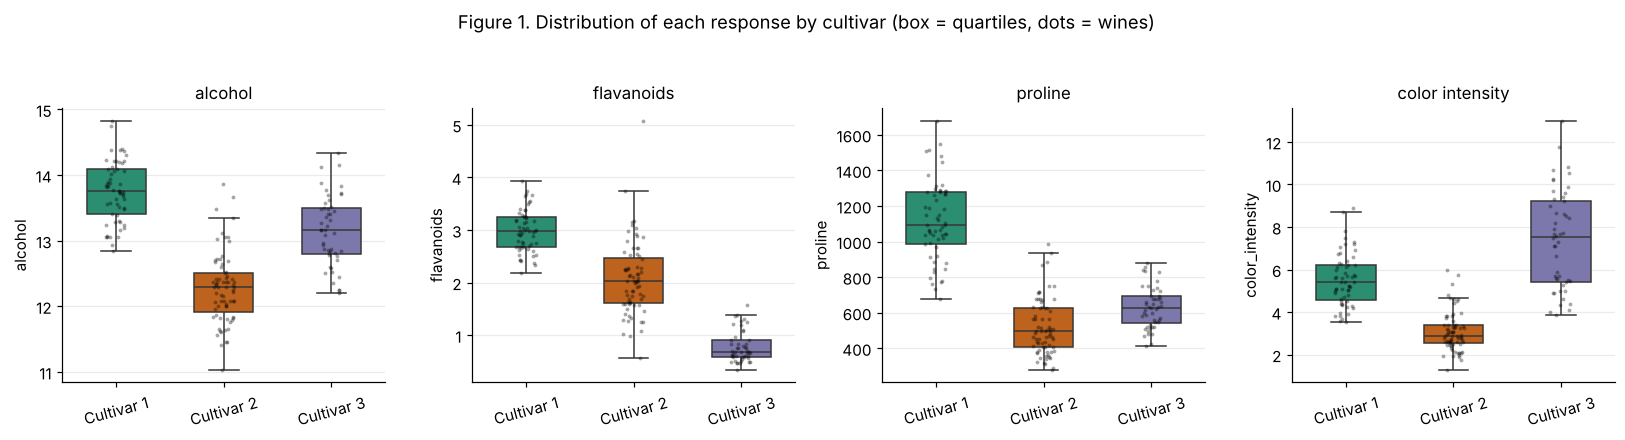

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, v in zip(axes, VARS):
    sns.boxplot(data=df, x="cultivar", y=v, order=CULT, palette=COLORS, width=0.55, fliersize=0, ax=ax, hue="cultivar", legend=False)
    sns.stripplot(data=df, x="cultivar", y=v, order=CULT, color="black", alpha=0.35, size=2.5, ax=ax)
    ax.set_title(v.replace("_", " ")); ax.set_xlabel(""); ax.tick_params(axis="x", labelrotation=15)
fig.suptitle("Figure 1. Distribution of each response by cultivar (box = quartiles, dots = wines)", y=1.04)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_distributions_by_cultivar.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Normality tests (Shapiro-Wilk and Kolmogorov-Smirnov)

**Why:** t-tests and ANOVA assume approximately normal data within groups (or residuals). Normality is therefore tested **within each cultivar** for each response variable.

**Hypotheses (for each of the 12 variable x cultivar samples):**

* **H0:** the sample comes from a normal distribution.
* **H1:** the sample does not come from a normal distribution.
* **Decision:** reject H0 if p < 0.05.

**Tests used**

1. **Shapiro-Wilk (W):** the most powerful general-purpose normality test at these sample sizes.
2. **Kolmogorov-Smirnov (D)** of the standardised sample against N(0,1). Because the mean and SD are *estimated from the same data*, the textbook KS p-value is too large (the test is conservative). Two p-values are therefore shown: the **plain KS** p (what `scipy.stats.kstest` returns) and the **Lilliefors-corrected KS** p, obtained from a 10,000-simulation null distribution of D with estimated parameters (validated in Section 2). The Lilliefors p is the one used for decisions.

Skewness and excess kurtosis are shown to explain *why* a sample fails.

In [6]:
rows = []
for v in VARS:
    for c in CULT:
        x = df.loc[df.cultivar == c, v].to_numpy(float)
        W, p_sw = stats.shapiro(x); D, p_ks, p_lf = ks_normal(x)
        rows.append({"variable": v, "cultivar": c, "n": len(x), "skew": stats.skew(x), "excess_kurtosis": stats.kurtosis(x),
                     "SW_W": W, "SW_p": p_sw, "KS_D": D, "KS_p_plain": p_ks, "KS_p_lilliefors": p_lf,
                     "SW_normal": p_sw >= ALPHA, "KS_normal": p_lf >= ALPHA})
norm_df = pd.DataFrame(rows)
RESULTS["normality"] = norm_df.to_dict("records")
shown = norm_df.copy()
for col in ["skew", "excess_kurtosis", "SW_W", "KS_D"]: shown[col] = shown[col].round(3)
for col in ["SW_p", "KS_p_plain", "KS_p_lilliefors"]: shown[col] = shown[col].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
shown["SW_normal"] = shown["SW_normal"].map({True: "normal", False: "reject"}); shown["KS_normal"] = shown["KS_normal"].map({True: "normal", False: "reject"})
display(Markdown("**Table 1. Normality tests within each cultivar (alpha = 0.05; decisions use the Lilliefors-corrected KS p).**"))
display(shown)
n_rej_sw, n_rej_ks = int((~norm_df.SW_normal).sum()), int((~norm_df.KS_normal).sum())
agree = int((norm_df.SW_normal == norm_df.KS_normal).sum())
display(Markdown(f"**Result:** Shapiro-Wilk rejects normality in **{n_rej_sw} of 12** samples and the Lilliefors-KS test in **{n_rej_ks} of 12**; "
                 f"the two tests give the same decision in **{agree} of 12** samples. The plain (uncorrected) KS test rejects in "
                 f"{int((norm_df.KS_p_plain < ALPHA).sum())} samples, illustrating its conservatism."))

**Table 1. Normality tests within each cultivar (alpha = 0.05; decisions use the Lilliefors-corrected KS p).**

,variable,cultivar,n,skew,excess_kurtosis,SW_W,SW_p,KS_D,KS_p_plain,KS_p_lilliefors,SW_normal,KS_normal
0,alcohol,Cultivar 1,59,0.069,-0.597,0.981,0.479,0.069,0.920,0.674,normal,normal
1,alcohol,Cultivar 2,71,0.568,0.614,0.972,0.114,0.108,0.358,0.039,normal,reject
2,alcohol,Cultivar 3,48,0.147,-0.666,0.981,0.641,0.093,0.766,0.365,normal,normal
3,flavanoids,Cultivar 1,59,0.261,-0.566,0.984,0.639,0.076,0.863,0.530,normal,normal
4,flavanoids,Cultivar 2,71,1.148,3.325,0.937,0.001,0.116,0.275,0.019,reject,reject
5,flavanoids,Cultivar 3,48,0.977,-0.003,0.892,<0.001,0.172,0.104,0.002,reject,reject
6,proline,Cultivar 1,59,0.224,-0.309,0.982,0.523,0.065,0.950,0.765,normal,normal
7,proline,Cultivar 2,71,0.873,0.419,0.939,0.002,0.133,0.151,0.004,reject,reject
8,proline,Cultivar 3,48,0.309,-0.524,0.977,0.458,0.063,0.985,0.906,normal,normal
9,color_intensity,Cultivar 1,59,0.575,0.016,0.968,0.125,0.073,0.889,0.589,normal,normal


**Result:** Shapiro-Wilk rejects normality in **4 of 12** samples and the Lilliefors-KS test in **6 of 12**; the two tests give the same decision in **10 of 12** samples. The plain (uncorrected) KS test rejects in 0 samples, illustrating its conservatism.

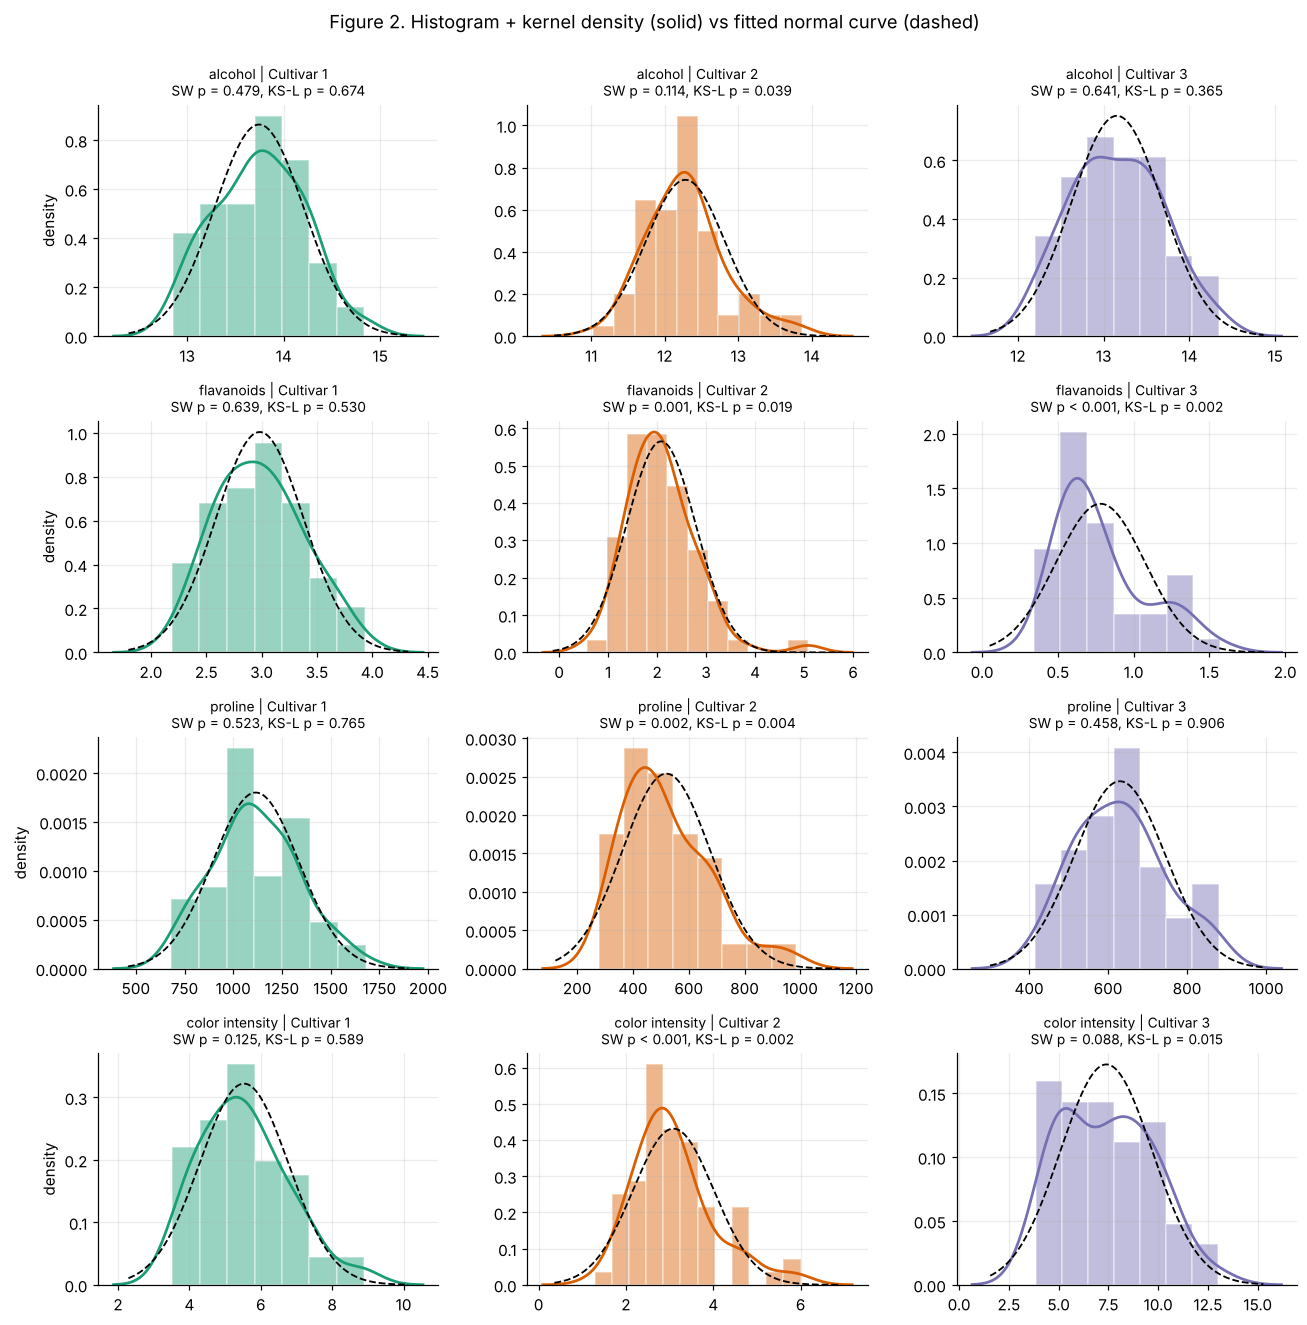

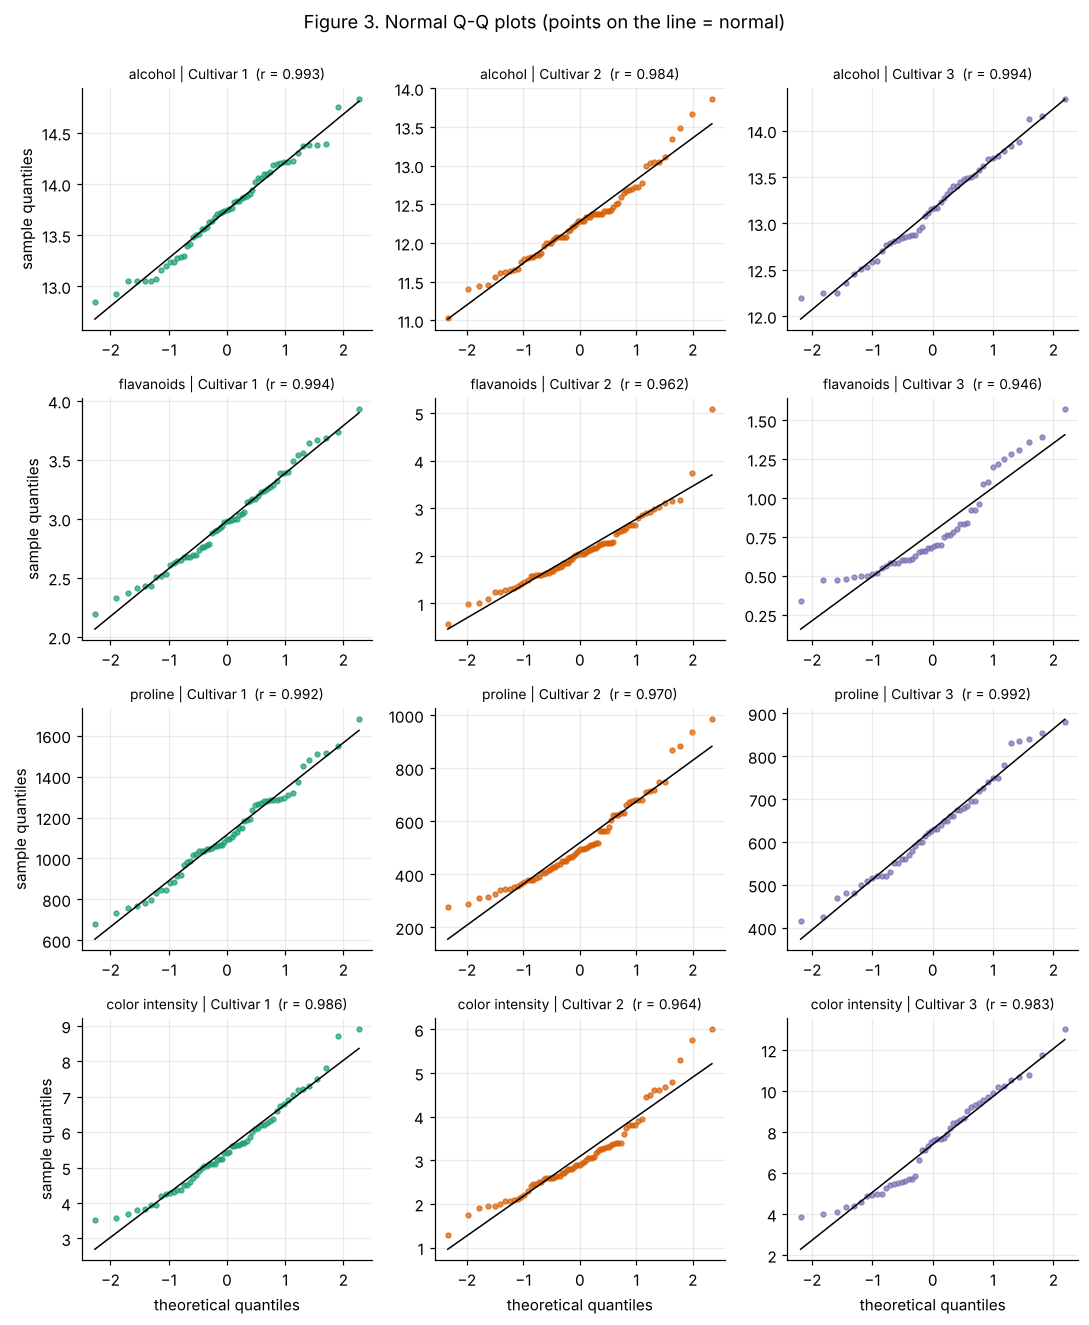

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(12, 12))
for i, v in enumerate(VARS):
    for j, c in enumerate(CULT):
        ax = axes[i, j]; x = df.loc[df.cultivar == c, v].to_numpy(float)
        ax.hist(x, bins="auto", density=True, color=COLORS[c], alpha=0.45, edgecolor="white")
        sns.kdeplot(x, ax=ax, color=COLORS[c], lw=1.8)
        g = np.linspace(x.min() - x.std(), x.max() + x.std(), 200); ax.plot(g, stats.norm.pdf(g, x.mean(), x.std(ddof=1)), "k--", lw=1.2)
        r = norm_df[(norm_df.variable == v) & (norm_df.cultivar == c)].iloc[0]
        ax.set_title(f"{v.replace('_', ' ')} | {c}\nSW {fmt_p(r.SW_p)}, KS-L {fmt_p(r.KS_p_lilliefors)}", fontsize=9)
        ax.set_ylabel("density" if j == 0 else ""); ax.set_xlabel("")
fig.suptitle("Figure 2. Histogram + kernel density (solid) vs fitted normal curve (dashed)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_histograms_normal_fit.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i, v in enumerate(VARS):
    for j, c in enumerate(CULT):
        ax = axes[i, j]; x = df.loc[df.cultivar == c, v].to_numpy(float)
        (osm, osr), (slope, icpt, rr) = stats.probplot(x, dist="norm")
        ax.scatter(osm, osr, s=10, color=COLORS[c], alpha=0.7); ax.plot(osm, slope * osm + icpt, "k-", lw=1)
        ax.set_title(f"{v.replace('_', ' ')} | {c}  (r = {rr:.3f})", fontsize=9)
        ax.set_xlabel("theoretical quantiles" if i == 3 else ""); ax.set_ylabel("sample quantiles" if j == 0 else "")
fig.suptitle("Figure 3. Normal Q-Q plots (points on the line = normal)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_qq_plots.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading Section 4.** Where Shapiro-Wilk and the corrected KS test both reject, the histograms and Q-Q plots show the reason (long right tail or heavy tails, see skewness above), and the non-parametric tests in Sections 5 and 6 are the safer primary results. Where neither rejects, the parametric tests are well supported. With samples of 48 to 71 per group, the t-test and ANOVA are fairly robust to mild non-normality, which is why both families are always reported side by side.

## 5. Two-sample tests: Student/Welch t-test and Mann-Whitney U

Two planned comparisons are made, both **Cultivar 1 vs Cultivar 2** (chosen in Section 1 before any testing):

| Comparison | Response | Reason for interest |
|---|---|---|
| A | `alcohol` | a roughly symmetric variable |
| B | `proline` | a right-skewed variable, where the t-test and the rank test may disagree |

**Hypotheses (identical form for A and B; mu = population mean, F = distribution function):**

* **t-test.** H0: mu(Cultivar 1) = mu(Cultivar 2). H1: mu(Cultivar 1) != mu(Cultivar 2). Both the **Student** (equal variances) and **Welch** (unequal variances) versions are run; the **95% CI** is for mu1 - mu2.
* **Mann-Whitney U.** H0: the two distributions are identical, equivalently P(X1 > X2) = 0.5. H1: one distribution is stochastically larger, P(X1 > X2) != 0.5. The **95% CI** is a bootstrap percentile interval (2,000 resamples) for the **Hodges-Lehmann shift**, the median of all pairwise differences.
* **Significance:** reject H0 if p < 0.05 (two-sided). Because two comparisons are planned, a **Bonferroni-adjusted p** (x 2) is also shown.

**Rule for the primary result (fixed in advance):** if Shapiro-Wilk does not reject normality in *both* groups, the **Welch t-test** is the primary result; otherwise the **Mann-Whitney U test** is. Equal-variance behaviour is checked with Levene's (median-centred) test, and Welch is preferred to Student whenever variances differ.

**Effect sizes:** Hedges' g (standardised mean difference, 95% CI), and for the rank test the rank-biserial correlation r = 2U/(n1 n2) - 1 and the common-language effect size P(X1 > X2) = U/(n1 n2).

In [8]:
def compare_two(var, g1="Cultivar 1", g2="Cultivar 2", n_planned=2):
    a = df.loc[df.cultivar == g1, var].to_numpy(float); b = df.loc[df.cultivar == g2, var].to_numpy(float)
    sw = (stats.shapiro(a).pvalue, stats.shapiro(b).pvalue); lev = stats.levene(a, b, center="median")
    st = stats.ttest_ind(a, b, equal_var=True); we = stats.ttest_ind(a, b, equal_var=False)
    d_s, lo_s, hi_s, df_s = student_ci(a, b); d_w, lo_w, hi_w, df_w = welch_ci(a, b)
    assert np.isclose(st.pvalue, 2 * stats.t.sf(abs(st.statistic), df_s)) and np.isclose(we.df, df_w)
    mw = stats.mannwhitneyu(a, b, alternative="two-sided"); n1, n2 = len(a), len(b)
    rbc = 2 * mw.statistic / (n1 * n2) - 1; cles = mw.statistic / (n1 * n2)
    hl, hl_lo, hl_hi = hodges_lehmann(a, b, r=np.random.default_rng(SEED)); g, g_lo, g_hi = hedges_g_ci(a, b)
    tbl = pd.DataFrame([
        {"Test": "Student t (equal var.)", "Statistic": st.statistic, "df": df_s, "p": st.pvalue, "p_Bonferroni": min(1, st.pvalue * n_planned),
         "Estimate": d_s, "CI95_low": lo_s, "CI95_high": hi_s, "Estimate_meaning": "mean difference"},
        {"Test": "Welch t (unequal var.)", "Statistic": we.statistic, "df": df_w, "p": we.pvalue, "p_Bonferroni": min(1, we.pvalue * n_planned),
         "Estimate": d_w, "CI95_low": lo_w, "CI95_high": hi_w, "Estimate_meaning": "mean difference"},
        {"Test": "Mann-Whitney U", "Statistic": mw.statistic, "df": np.nan, "p": mw.pvalue, "p_Bonferroni": min(1, mw.pvalue * n_planned),
         "Estimate": hl, "CI95_low": hl_lo, "CI95_high": hl_hi, "Estimate_meaning": "Hodges-Lehmann shift"}])
    both_normal = sw[0] >= ALPHA and sw[1] >= ALPHA
    primary = "Welch t-test" if both_normal else "Mann-Whitney U"
    return {"var": var, "g1": g1, "g2": g2, "n": (n1, n2), "means": (a.mean(), b.mean()), "sds": (a.std(ddof=1), b.std(ddof=1)),
            "medians": (float(np.median(a)), float(np.median(b))), "shapiro_p": sw, "levene_p": lev.pvalue, "table": tbl,
            "hedges_g": (g, g_lo, g_hi), "rank_biserial": rbc, "cles": cles, "primary": primary,
            "primary_p": (we.pvalue if both_normal else mw.pvalue), "a": a, "b": b}

TWO = {v: compare_two(v) for v in ["alcohol", "proline"]}
for v, r in TWO.items():
    t = r["table"].copy()
    for col in ["Statistic", "df", "Estimate", "CI95_low", "CI95_high"]: t[col] = t[col].round(3)
    for col in ["p", "p_Bonferroni"]: t[col] = t[col].map(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
    display(Markdown(f"### Comparison {'A' if v == 'alcohol' else 'B'}: `{v}`, {r['g1']} (n = {r['n'][0]}) vs {r['g2']} (n = {r['n'][1]})"))
    display(Markdown(f"Means {r['means'][0]:.2f} vs {r['means'][1]:.2f} (SD {r['sds'][0]:.2f} vs {r['sds'][1]:.2f}); medians {r['medians'][0]:.1f} vs {r['medians'][1]:.1f}. "
                     f"Shapiro-Wilk p = {r['shapiro_p'][0]:.3f} / {r['shapiro_p'][1]:.3f}; Levene (equal variances) {fmt_p(r['levene_p'])}."))
    display(t)
    g, gl, gh = r["hedges_g"]
    display(Markdown(f"Effect sizes: Hedges' g = **{g:.2f}** (95% CI {gl:.2f} to {gh:.2f}); rank-biserial r = **{r['rank_biserial']:.2f}**; "
                     f"P(Cultivar 1 > Cultivar 2) = **{r['cles']:.2f}**. By the pre-set rule the primary result is the **{r['primary']}** ({fmt_p(r['primary_p'])}) "
                     f"-> **{'reject H0' if r['primary_p'] < ALPHA else 'fail to reject H0'}** at alpha = 0.05."))
RESULTS["two_sample"] = {v: {k: (r[k] if k != "table" else r["table"].to_dict("records")) for k in
                             ["var", "g1", "g2", "n", "means", "sds", "medians", "shapiro_p", "levene_p", "table", "hedges_g", "rank_biserial", "cles", "primary", "primary_p"]}
                         for v, r in TWO.items()}

### Comparison A: `alcohol`, Cultivar 1 (n = 59) vs Cultivar 2 (n = 71)

Means 13.74 vs 12.28 (SD 0.46 vs 0.54); medians 13.8 vs 12.3. Shapiro-Wilk p = 0.479 / 0.114; Levene (equal variances) p = 0.577.

,Test,Statistic,df,p,p_Bonferroni,Estimate,CI95_low,CI95_high,Estimate_meaning
0,Student t (equal var.),16.479,128.000,<0.001,<0.001,1.466,1.290,1.642,mean difference
1,Welch t (unequal var.),16.711,127.847,<0.001,<0.001,1.466,1.292,1.640,mean difference
2,Mann-Whitney U,4079.500,NaN,<0.001,<0.001,1.490,1.310,1.680,Hodges-Lehmann shift


Effect sizes: Hedges' g = **2.89** (95% CI 2.39 to 3.38); rank-biserial r = **0.95**; P(Cultivar 1 > Cultivar 2) = **0.97**. By the pre-set rule the primary result is the **Welch t-test** (p < 0.001) -> **reject H0** at alpha = 0.05.

### Comparison B: `proline`, Cultivar 1 (n = 59) vs Cultivar 2 (n = 71)

Means 1115.71 vs 519.51 (SD 221.52 vs 157.21); medians 1095.0 vs 495.0. Shapiro-Wilk p = 0.523 / 0.002; Levene (equal variances) p = 0.011.

,Test,Statistic,df,p,p_Bonferroni,Estimate,CI95_low,CI95_high,Estimate_meaning
0,Student t (equal var.),17.899,128.000,<0.001,<0.001,596.205,530.297,662.113,mean difference
1,Welch t (unequal var.),17.357,101.917,<0.001,<0.001,596.205,528.074,664.336,mean difference
2,Mann-Whitney U,4133.000,NaN,<0.001,<0.001,601.000,533.000,665.000,Hodges-Lehmann shift


Effect sizes: Hedges' g = **3.13** (95% CI 2.62 to 3.65); rank-biserial r = **0.97**; P(Cultivar 1 > Cultivar 2) = **0.99**. By the pre-set rule the primary result is the **Mann-Whitney U** (p < 0.001) -> **reject H0** at alpha = 0.05.

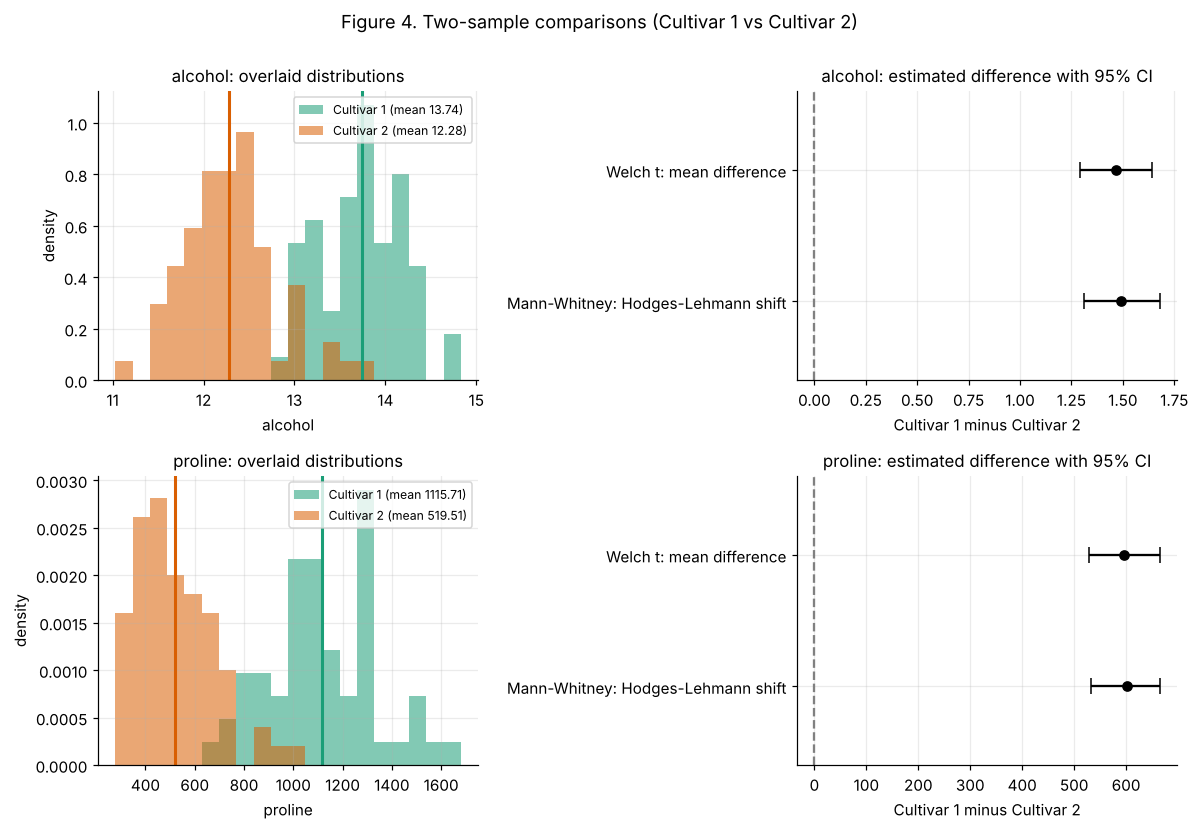

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for row, (v, r) in enumerate(TWO.items()):
    a, b = r["a"], r["b"]; ax = axes[row, 0]
    bins = np.histogram_bin_edges(np.concatenate([a, b]), bins=20)
    ax.hist(a, bins=bins, alpha=0.55, color=COLORS[r["g1"]], label=f"{r['g1']} (mean {a.mean():.2f})", density=True)
    ax.hist(b, bins=bins, alpha=0.55, color=COLORS[r["g2"]], label=f"{r['g2']} (mean {b.mean():.2f})", density=True)
    ax.axvline(a.mean(), color=COLORS[r["g1"]], lw=2); ax.axvline(b.mean(), color=COLORS[r["g2"]], lw=2)
    ax.set_title(f"{v}: overlaid distributions"); ax.set_xlabel(v); ax.set_ylabel("density"); ax.legend(fontsize=8)
    ax = axes[row, 1]; t = r["table"]
    est = [t.loc[1, "Estimate"], t.loc[2, "Estimate"]]; lo = [t.loc[1, "CI95_low"], t.loc[2, "CI95_low"]]; hi = [t.loc[1, "CI95_high"], t.loc[2, "CI95_high"]]
    ax.errorbar(est, [1, 0], xerr=[np.array(est) - lo, np.array(hi) - est], fmt="o", color="black", capsize=5)
    ax.axvline(0, color="grey", ls="--"); ax.set_yticks([1, 0]); ax.set_yticklabels(["Welch t: mean difference", "Mann-Whitney: Hodges-Lehmann shift"])
    ax.set_title(f"{v}: estimated difference with 95% CI"); ax.set_xlabel("Cultivar 1 minus Cultivar 2"); ax.set_ylim(-0.6, 1.6)
fig.suptitle("Figure 4. Two-sample comparisons (Cultivar 1 vs Cultivar 2)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_two_sample_comparisons.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. One-Way ANOVA with Tukey HSD post-hoc analysis

**Question:** does mean `proline` concentration differ across the three cultivars? (`proline` was chosen in Section 1 because it is right-skewed, so the robustness of the conclusion matters.)

**Hypotheses**

* **H0:** mu(Cultivar 1) = mu(Cultivar 2) = mu(Cultivar 3) (all three population means are equal).
* **H1:** at least one cultivar mean differs from the others.
* **Decision:** reject H0 if the F-test p < 0.05.

**Assumptions checked in 6.2:** independence (separate wines), normality of residuals (Shapiro-Wilk, Q-Q), equal variances (Levene). If equal variances are rejected, the **Welch ANOVA** is the more trustworthy omnibus test, and the non-parametric **Kruskal-Wallis** test is run as a distribution-free check.

**Post-hoc (Section 6.4):** if H0 is rejected, **Tukey HSD** tests every pair (H0: mu_i = mu_j) with the family-wise error held at 5%, and gives simultaneous **95% CIs** for each mean difference. Because Tukey assumes equal variances, the **Games-Howell** procedure (valid under unequal variances) and Holm-adjusted pairwise Mann-Whitney tests are shown as robustness checks.

In [10]:
groups = [df.loc[df.cultivar == c, "proline"].to_numpy(float) for c in CULT]
ow = anova_oneway(groups); assert np.isclose(ow["p"], stats.f_oneway(*groups).pvalue)
tcrit = lambda n: stats.t.ppf(1 - ALPHA / 2, n - 1)
desc = pd.DataFrame({"cultivar": CULT, "n": [len(g) for g in groups], "mean": [g.mean() for g in groups], "SD": [g.std(ddof=1) for g in groups],
                     "mean_CI95_low": [g.mean() - tcrit(len(g)) * g.std(ddof=1) / math.sqrt(len(g)) for g in groups],
                     "mean_CI95_high": [g.mean() + tcrit(len(g)) * g.std(ddof=1) / math.sqrt(len(g)) for g in groups]}).round(1)
display(Markdown("**Table 3. Proline by cultivar with 95% CI for each mean.**")); display(desc)

anova_tbl = pd.DataFrame([{"Source": "Between cultivars", "SS": ow["ssb"], "df": ow["dfb"], "MS": ow["msb"], "F": ow["F"], "p": ow["p"]},
                          {"Source": "Within (residual)", "SS": ow["ssw"], "df": ow["dfw"], "MS": ow["msw"], "F": np.nan, "p": np.nan},
                          {"Source": "Total", "SS": ow["sst"], "df": ow["dfb"] + ow["dfw"], "MS": np.nan, "F": np.nan, "p": np.nan}])
display(Markdown("**Table 4. One-way ANOVA table.**")); display(anova_tbl.round(4))
display(Markdown(f"**F({ow['dfb']}, {ow['dfw']}) = {ow['F']:.2f}, {fmt_p(ow['p'])}**; effect sizes: eta-squared = **{ow['eta2']:.3f}**, omega-squared = **{ow['omega2']:.3f}** "
                 f"(share of proline variance associated with cultivar). Decision: **{'reject H0' if ow['p'] < ALPHA else 'fail to reject H0'}** at alpha = 0.05."))

**Table 3. Proline by cultivar with 95% CI for each mean.**

,cultivar,n,mean,SD,mean_CI95_low,mean_CI95_high
0,Cultivar 1,59,1115.7,221.5,1058.0,1173.4
1,Cultivar 2,71,519.5,157.2,482.3,556.7
2,Cultivar 3,48,629.9,115.1,596.5,663.3


**Table 4. One-way ANOVA table.**

,Source,SS,df,MS,F,p
0,Between cultivars,1.235366e+07,2,6.176832e+06,207.9204,0.0
1,Within (residual),5.198844e+06,175,2.970768e+04,NaN,NaN
2,Total,1.755251e+07,177,NaN,NaN,NaN


**F(2, 175) = 207.92, p < 0.001**; effect sizes: eta-squared = **0.704**, omega-squared = **0.699** (share of proline variance associated with cultivar). Decision: **reject H0** at alpha = 0.05.

### 6.2 Assumption checks for the one-way model

**Table 5. Assumption checks and assumption-light alternatives to the omnibus F-test.**

,Check,Statistic,p,Reading
0,Residual normality (Shapiro-Wilk),0.982,0.0210,normality rejected
1,"Equal variances (Levene, median-centred)",8.513,<0.001,equal variances rejected
2,"Welch ANOVA F(2, 111.8)",153.841,<0.001,groups differ
3,Kruskal-Wallis H(2),119.060,<0.001,groups differ


Kruskal-Wallis effect size epsilon-squared = **0.669**. All three omnibus tests (classical F, Welch F, Kruskal-Wallis) agree on whether the cultivars differ.

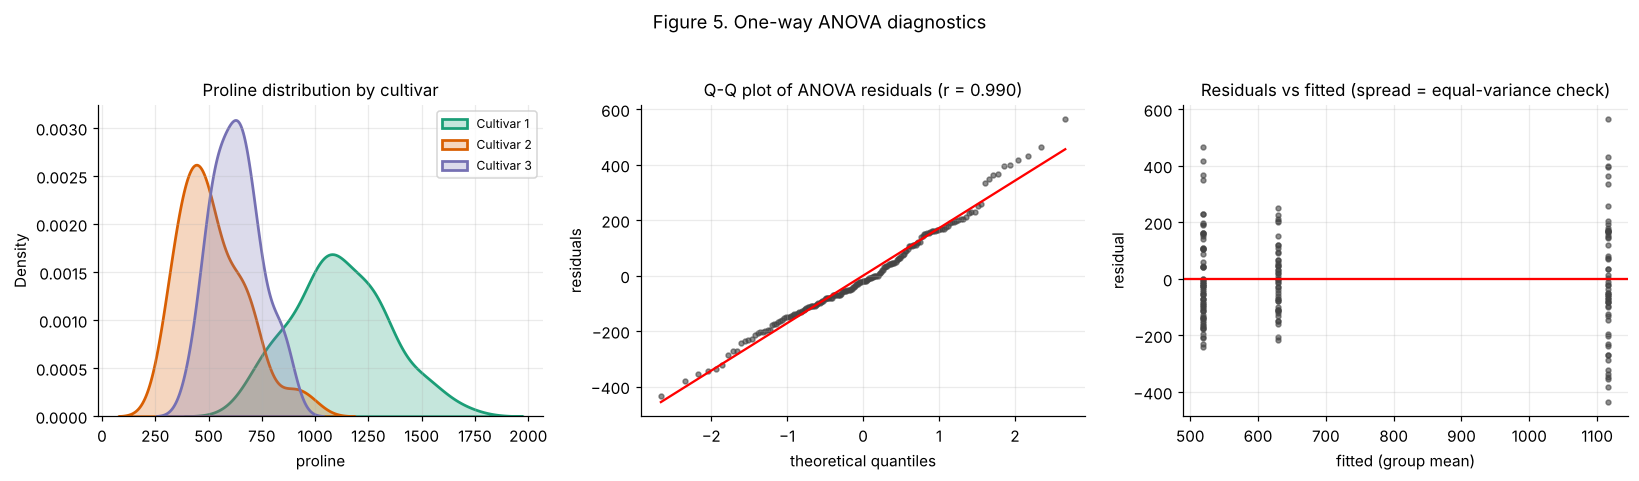

In [11]:
resid_ow = np.concatenate([g - g.mean() for g in groups])
sw_ow = stats.shapiro(resid_ow); lev_ow = stats.levene(*groups, center="median")
F_w, d1_w, d2_w, p_w = welch_anova(groups); kw = stats.kruskal(*groups)
eps2 = (kw.statistic - len(groups) + 1) / (len(resid_ow) - len(groups))     # epsilon-squared effect size for Kruskal-Wallis
chk = pd.DataFrame([
    {"Check": "Residual normality (Shapiro-Wilk)", "Statistic": sw_ow.statistic, "p": sw_ow.pvalue, "Reading": "normality " + ("not rejected" if sw_ow.pvalue >= ALPHA else "rejected")},
    {"Check": "Equal variances (Levene, median-centred)", "Statistic": lev_ow.statistic, "p": lev_ow.pvalue, "Reading": "equal variances " + ("not rejected" if lev_ow.pvalue >= ALPHA else "rejected")},
    {"Check": f"Welch ANOVA  F({d1_w}, {d2_w:.1f})", "Statistic": F_w, "p": p_w, "Reading": "groups differ" if p_w < ALPHA else "no difference"},
    {"Check": f"Kruskal-Wallis  H({len(groups) - 1})", "Statistic": kw.statistic, "p": kw.pvalue, "Reading": "groups differ" if kw.pvalue < ALPHA else "no difference"}])
chk["Statistic"] = chk["Statistic"].round(3); chk["p"] = chk["p"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
display(Markdown("**Table 5. Assumption checks and assumption-light alternatives to the omnibus F-test.**")); display(chk)
display(Markdown(f"Kruskal-Wallis effect size epsilon-squared = **{eps2:.3f}**. All three omnibus tests (classical F, Welch F, Kruskal-Wallis) "
                 f"{'agree' if (ow['p'] < ALPHA) == (p_w < ALPHA) == (kw.pvalue < ALPHA) else 'do NOT agree'} on whether the cultivars differ."))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for g, c in zip(groups, CULT): sns.kdeplot(g, ax=axes[0], color=COLORS[c], fill=True, alpha=0.25, lw=1.8, label=c)
axes[0].set_title("Proline distribution by cultivar"); axes[0].set_xlabel("proline"); axes[0].legend(fontsize=8)
(osm, osr), (sl, ic, rr) = stats.probplot(resid_ow, dist="norm"); axes[1].scatter(osm, osr, s=10, alpha=0.6, color="#444"); axes[1].plot(osm, sl * osm + ic, "r-")
axes[1].set_title(f"Q-Q plot of ANOVA residuals (r = {rr:.3f})"); axes[1].set_xlabel("theoretical quantiles"); axes[1].set_ylabel("residuals")
fitted = np.concatenate([np.full(len(g), g.mean()) for g in groups]); axes[2].scatter(fitted, resid_ow, s=10, alpha=0.6, color="#444"); axes[2].axhline(0, color="r")
axes[2].set_title("Residuals vs fitted (spread = equal-variance check)"); axes[2].set_xlabel("fitted (group mean)"); axes[2].set_ylabel("residual")
fig.suptitle("Figure 5. One-way ANOVA diagnostics", y=1.03); fig.tight_layout(); fig.savefig(FIG_DIR / "fig5_oneway_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Tukey HSD post-hoc comparisons

**Hypotheses for each pair (i, j):** H0: mu_i = mu_j versus H1: mu_i != mu_j, tested at a family-wise error rate of 5% across the three pairs. The difference is mean_i minus mean_j; the CI is the simultaneous 95% Tukey interval (an interval that excludes 0 is equivalent to p_adj < 0.05).

**Table 6. Tukey HSD (mean difference in proline, simultaneous 95% CI) with two robustness checks.**

,comparison,diff,ci_low,ci_high,p_adj,significant,p_GamesHowell,p_MWU_Holm
0,Cultivar 1 - Cultivar 2,596.2,524.4,668.0,<0.001,True,<0.001,<0.001
1,Cultivar 1 - Cultivar 3,485.8,406.6,565.0,<0.001,True,<0.001,<0.001
2,Cultivar 2 - Cultivar 3,-110.4,-186.5,-34.3,0.0022,True,<0.001,<0.001


**Tukey HSD:** 3 of 3 pairs differ significantly (Cultivar 1 - Cultivar 2; Cultivar 1 - Cultivar 3; Cultivar 2 - Cultivar 3). Games-Howell reaches the same decisions for all pairs: **True**; Holm-adjusted Mann-Whitney does as well: **True**.

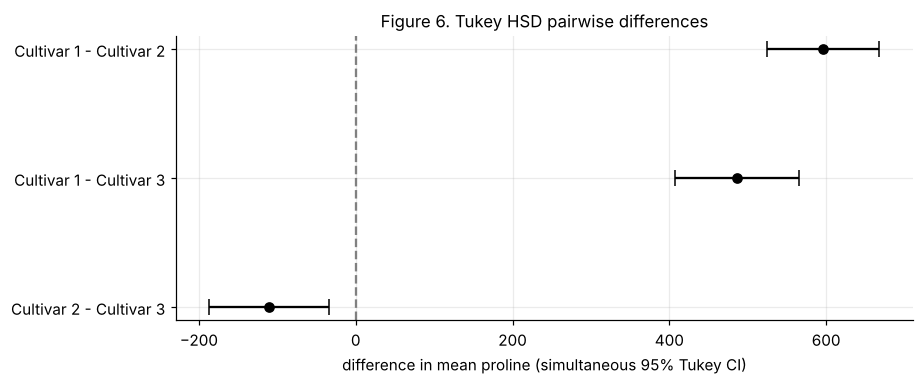

In [12]:
tk = tukey_table(groups, CULT); gh = games_howell(groups, CULT)
mw_pairs = []
for i in range(3):
    for j in range(i + 1, 3):
        mw_pairs.append({"comparison": f"{CULT[i]} - {CULT[j]}", "p_raw": stats.mannwhitneyu(groups[i], groups[j], alternative="two-sided").pvalue})
mw_pairs = pd.DataFrame(mw_pairs); mw_pairs["p_Holm"] = holm(mw_pairs.p_raw)
post = tk.merge(gh[["comparison", "p"]].rename(columns={"p": "p_GamesHowell"}), on="comparison").merge(mw_pairs[["comparison", "p_Holm"]].rename(columns={"p_Holm": "p_MWU_Holm"}), on="comparison")
RESULTS["oneway"] = {"F": ow["F"], "dfb": ow["dfb"], "dfw": ow["dfw"], "p": ow["p"], "eta2": ow["eta2"], "omega2": ow["omega2"], "welch_F": F_w, "welch_p": p_w,
                     "kruskal_H": kw.statistic, "kruskal_p": kw.pvalue, "levene_p": lev_ow.pvalue, "shapiro_resid_p": sw_ow.pvalue,
                     "means": dict(zip(CULT, [g.mean() for g in groups])), "tukey": post.to_dict("records")}
shown = post.copy()
for col in ["diff", "ci_low", "ci_high"]: shown[col] = shown[col].round(1)
for col in ["p_adj", "p_GamesHowell", "p_MWU_Holm"]: shown[col] = shown[col].map(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
display(Markdown("**Table 6. Tukey HSD (mean difference in proline, simultaneous 95% CI) with two robustness checks.**")); display(shown)
sig_pairs = [r.comparison for r in post.itertuples() if r.significant]
display(Markdown(f"**Tukey HSD:** {len(sig_pairs)} of 3 pairs differ significantly ({'; '.join(sig_pairs) if sig_pairs else 'none'}). "
                 f"Games-Howell reaches the same decisions for all pairs: **{bool(((post.p_GamesHowell < ALPHA) == post.significant).all())}**; "
                 f"Holm-adjusted Mann-Whitney does as well: **{bool(((post.p_MWU_Holm < ALPHA) == post.significant).all())}**."))

fig, ax = plt.subplots(figsize=(8.5, 3.6)); ypos = np.arange(len(post))[::-1]
ax.errorbar(post["diff"], ypos, xerr=[post["diff"] - post["ci_low"], post["ci_high"] - post["diff"]], fmt="o", color="black", capsize=5)
ax.axvline(0, color="grey", ls="--"); ax.set_yticks(ypos); ax.set_yticklabels(post["comparison"])
ax.set_xlabel("difference in mean proline (simultaneous 95% Tukey CI)"); ax.set_title("Figure 6. Tukey HSD pairwise differences")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig6_tukey_oneway.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Two-Way ANOVA (with interaction) and Tukey HSD

**Question:** does `flavanoids` content depend on **cultivar** (3 levels), on **magnesium level** (Low vs High, split at the sample median), or on their **combination**? (`flavanoids` and the magnesium split were fixed in Section 1.)

**Model:** flavanoids = grand mean + cultivar effect + magnesium effect + cultivar x magnesium interaction + error. The design is **unbalanced** (cells hold 16 to 52 wines), so **Type III sums of squares** with sum-to-zero (effect) coding are the primary table, and Type II is shown for comparison. Both were validated against closed-form sums of squares in Section 2.

**Three pairs of hypotheses (each tested at alpha = 0.05):**

| Effect | H0 | H1 |
|---|---|---|
| Cultivar (main effect) | all three cultivar means are equal (averaged over magnesium levels) | at least one cultivar mean differs |
| Magnesium level (main effect) | Low-Mg and High-Mg means are equal (averaged over cultivars) | the two means differ |
| Cultivar x Magnesium (interaction) | the magnesium effect is the same in every cultivar (no interaction) | the magnesium effect differs between cultivars |

Because an interaction changes how main effects should be read, the interaction is interpreted **first**. If it is significant, simple effects (magnesium effect within each cultivar, Bonferroni-adjusted over 3 tests) are reported. Assumptions: independence, normal residuals (Shapiro-Wilk, Q-Q) and equal cell variances (Levene). A **rank-transformed ANOVA** is the distribution-free robustness check. Tukey HSD is then applied to all 6 cell means (15 pairs).

In [13]:
med_mg = df["magnesium"].median()
df["mg_level"] = np.where(df["magnesium"] > med_mg, "High Mg", "Low Mg")
MG = ["Low Mg", "High Mg"]
print(f"Median magnesium = {med_mg:.0f}; Low Mg = at or below the median, High Mg = above it.")
cellcount = pd.crosstab(df.cultivar, df.mg_level).reindex(index=CULT, columns=MG)
display(Markdown("**Table 7. Design: number of wines in each cultivar x magnesium cell (unbalanced).**")); display(cellcount)

res2 = anova2(df, "flavanoids", "cultivar", "mg_level", CULT, MG); t3, t2 = res2["type3"].copy(), res2["type2"].copy()
def fmt_anova(t):
    t = t.copy(); t["p"] = t["p"].map(lambda p: "" if pd.isna(p) else ("<0.001" if p < 0.001 else f"{p:.4f}"))
    for c_ in ["SS", "MS", "F", "partial_eta2"]: t[c_] = t[c_].round(3)
    return t.fillna("")
display(Markdown("**Table 8. Two-way ANOVA, Type III sums of squares (primary).**")); display(fmt_anova(t3))
display(Markdown("**Table 9. Two-way ANOVA, Type II sums of squares (comparison).**")); display(fmt_anova(t2))
ranked = df.assign(rank_flav=stats.rankdata(df["flavanoids"])); rk = anova2(ranked, "rank_flav", "cultivar", "mg_level", CULT, MG)["type3"]
display(Markdown("**Table 10. Robustness: Type III ANOVA on the ranks of flavanoids (non-parametric check).**")); display(fmt_anova(rk))

def line(t, name):
    r = t.set_index("Source").loc[name]; return f"F({int(r['df'])}, {int(t.set_index('Source').loc['Residual','df'])}) = {r['F']:.2f}, {fmt_p(r['p'])}, partial eta-squared = {r['partial_eta2']:.3f}"
src_int = "cultivar x mg_level"
display(Markdown(f"**Cultivar:** {line(t3, 'cultivar')} -> **{'reject H0' if t3.set_index('Source').loc['cultivar','p'] < ALPHA else 'fail to reject H0'}**.  \n"
                 f"**Magnesium level:** {line(t3, 'mg_level')} -> **{'reject H0' if t3.set_index('Source').loc['mg_level','p'] < ALPHA else 'fail to reject H0'}**.  \n"
                 f"**Interaction:** {line(t3, src_int)} -> **{'reject H0' if t3.set_index('Source').loc[src_int,'p'] < ALPHA else 'fail to reject H0'}**."))
RESULTS["twoway"] = {"cell_counts": cellcount.to_dict(), "type3": res2["type3"].to_dict("records"), "type2": res2["type2"].to_dict("records"), "rank_type3": rk.to_dict("records")}

Median magnesium = 98; Low Mg = at or below the median, High Mg = above it.


**Table 7. Design: number of wines in each cultivar x magnesium cell (unbalanced).**

mg_level,Low Mg,High Mg
cultivar,,
Cultivar 1,16,43
Cultivar 2,52,19
Cultivar 3,28,20


**Table 8. Two-way ANOVA, Type III sums of squares (primary).**

,Source,SS,df,MS,F,p,partial_eta2
0,cultivar,104.910,2,52.455,196.396,<0.001,0.695
1,mg_level,0.773,1,0.773,2.894,0.0907,0.017
2,cultivar x mg_level,1.525,2,0.763,2.856,0.0603,0.032
3,Residual,45.939,172,0.267,,,


**Table 9. Two-way ANOVA, Type II sums of squares (comparison).**

,Source,SS,df,MS,F,p,partial_eta2
0,cultivar,118.415,2,59.208,221.677,<0.001,0.72
1,mg_level,0.609,1,0.609,2.28,0.1329,0.013
2,cultivar x mg_level,1.525,2,0.763,2.856,0.0603,0.032
3,Residual,45.939,172,0.267,,,


**Table 10. Robustness: Type III ANOVA on the ranks of flavanoids (non-parametric check).**

,Source,SS,df,MS,F,p,partial_eta2
0,cultivar,276650.224,2,138325.112,206.064,<0.001,0.706
1,mg_level,2190.821,1,2190.821,3.264,0.0726,0.019
2,cultivar x mg_level,6493.266,2,3246.633,4.837,0.0090,0.053
3,Residual,115458.656,172,671.271,,,


**Cultivar:** F(2, 172) = 196.40, p < 0.001, partial eta-squared = 0.695 -> **reject H0**.  
**Magnesium level:** F(1, 172) = 2.89, p = 0.091, partial eta-squared = 0.017 -> **fail to reject H0**.  
**Interaction:** F(2, 172) = 2.86, p = 0.060, partial eta-squared = 0.032 -> **fail to reject H0**.

**Table 11. Cell means of flavanoids with 95% CI.**

,cultivar,mg_level,n,mean,SD,CI95_low,CI95_high
0,Cultivar 1,Low Mg,16,2.749,0.399,2.536,2.961
1,Cultivar 1,High Mg,43,3.069,0.364,2.957,3.181
2,Cultivar 2,Low Mg,52,2.116,0.608,1.947,2.285
3,Cultivar 2,High Mg,19,1.985,0.935,1.534,2.436
4,Cultivar 3,Low Mg,28,0.680,0.220,0.594,0.765
5,Cultivar 3,High Mg,20,0.924,0.328,0.770,1.078


**Assumptions:** residual normality Shapiro-Wilk W = 0.919, p < 0.001; equal cell variances Levene W = 5.98, p < 0.001. The rank-based ANOVA (Table 10) does NOT agree with the classical decisions for all three effects.

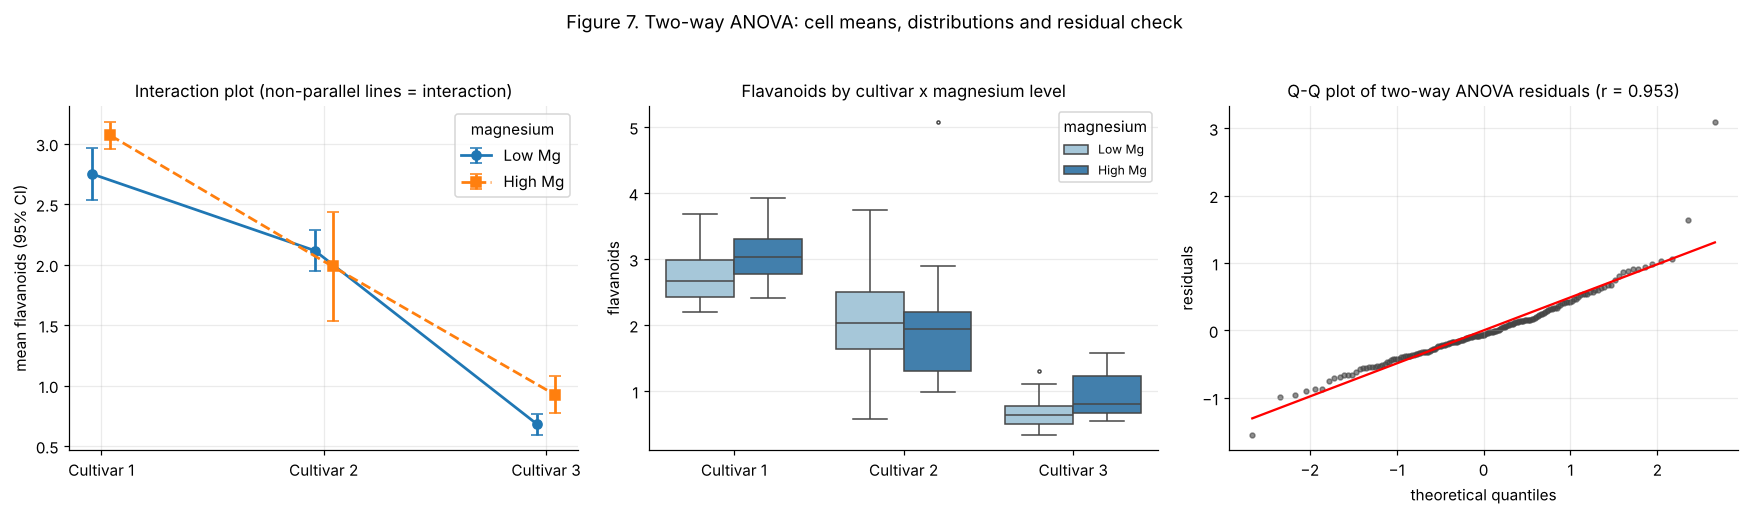

In [14]:
cells_ = df.groupby(["cultivar", "mg_level"])["flavanoids"].agg(["count", "mean", "std"]).reindex(pd.MultiIndex.from_product([CULT, MG])).reset_index()
cells_.columns = ["cultivar", "mg_level", "n", "mean", "SD"]
cells_["CI95_low"] = cells_["mean"] - stats.t.ppf(0.975, cells_.n - 1) * cells_.SD / np.sqrt(cells_.n)
cells_["CI95_high"] = cells_["mean"] + stats.t.ppf(0.975, cells_.n - 1) * cells_.SD / np.sqrt(cells_.n)
display(Markdown("**Table 11. Cell means of flavanoids with 95% CI.**")); display(cells_.round(3))

resid2 = res2["resid"]; cell_groups = [df.loc[(df.cultivar == c) & (df.mg_level == m), "flavanoids"].to_numpy(float) for c in CULT for m in MG]
sw2 = stats.shapiro(resid2); lev2 = stats.levene(*cell_groups, center="median")
display(Markdown(f"**Assumptions:** residual normality Shapiro-Wilk W = {sw2.statistic:.3f}, {fmt_p(sw2.pvalue)}; equal cell variances Levene W = {lev2.statistic:.2f}, {fmt_p(lev2.pvalue)}. "
                 f"The rank-based ANOVA (Table 10) {'agrees' if all((rk.set_index('Source').loc[s, 'p'] < ALPHA) == (t3.set_index('Source').loc[s, 'p'] < ALPHA) for s in ['cultivar', 'mg_level', src_int]) else 'does NOT agree'} with the classical decisions for all three effects."))
RESULTS["twoway"].update({"shapiro_resid_p": sw2.pvalue, "levene_p": lev2.pvalue, "cells": cells_.to_dict("records")})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for m, mk, ls in zip(MG, ["o", "s"], ["-", "--"]):
    s = cells_[cells_.mg_level == m]; x = np.arange(3) + (0.04 if m == "High Mg" else -0.04)
    axes[0].errorbar(x, s["mean"], yerr=[s["mean"] - s.CI95_low, s.CI95_high - s["mean"]], marker=mk, ls=ls, capsize=4, label=m, lw=1.8)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(CULT); axes[0].set_ylabel("mean flavanoids (95% CI)"); axes[0].legend(title="magnesium")
axes[0].set_title("Interaction plot (non-parallel lines = interaction)")
sns.boxplot(data=df, x="cultivar", y="flavanoids", hue="mg_level", order=CULT, hue_order=MG, ax=axes[1], palette=["#9ecae1", "#3182bd"], fliersize=2)
axes[1].set_title("Flavanoids by cultivar x magnesium level"); axes[1].set_xlabel(""); axes[1].legend(title="magnesium", fontsize=8)
(osm, osr), (sl, ic, rr) = stats.probplot(resid2, dist="norm"); axes[2].scatter(osm, osr, s=10, alpha=0.6, color="#444"); axes[2].plot(osm, sl * osm + ic, "r-")
axes[2].set_title(f"Q-Q plot of two-way ANOVA residuals (r = {rr:.3f})"); axes[2].set_xlabel("theoretical quantiles"); axes[2].set_ylabel("residuals")
fig.suptitle("Figure 7. Two-way ANOVA: cell means, distributions and residual check", y=1.03)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig7_twoway_anova.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.4 Simple effects of magnesium within each cultivar
Reported to interpret the interaction. For each cultivar: H0: mean(High Mg) = mean(Low Mg) versus H1: they differ (Welch t-test, 95% CI for High minus Low, Bonferroni-adjusted over the 3 tests).

### 7.5 Tukey HSD across the six cultivar x magnesium cells
For each pair of cells: H0: the two cell means are equal; simultaneous 95% CIs control the family-wise error over all 15 pairs.

**Table 12. Simple effects: High-Mg minus Low-Mg flavanoids within each cultivar.**

,cultivar,n_High,n_Low,High_minus_Low,CI95_low,CI95_high,t,df,p,p_Bonferroni
0,Cultivar 1,43,16,0.321,0.085,0.556,2.807,24.892,0.0096,0.0287
1,Cultivar 2,19,52,-0.131,-0.607,0.345,-0.569,23.794,0.5746,1.0000
2,Cultivar 3,20,28,0.244,0.072,0.416,2.898,30.912,0.0069,0.0206


**Table 13. Tukey HSD on the 6 cells (labels = cultivar number | magnesium level; difference = first minus second).**

,comparison,diff,ci_low,ci_high,p_adj,significant
0,1|Low - 1|High,-0.321,-0.757,0.116,0.2829,False
1,1|Low - 2|Low,0.633,0.207,1.059,<0.001,True
2,1|Low - 2|High,0.764,0.259,1.269,<0.001,True
3,1|Low - 3|Low,2.069,1.602,2.536,<0.001,True
4,1|Low - 3|High,1.825,1.325,2.324,<0.001,True
5,1|High - 2|Low,0.953,0.646,1.260,<0.001,True
6,1|High - 2|High,1.085,0.674,1.495,<0.001,True
7,1|High - 3|Low,2.390,2.028,2.751,<0.001,True
8,1|High - 3|High,2.145,1.742,2.548,<0.001,True
9,2|Low - 2|High,0.131,-0.268,0.531,0.9335,False


**Tukey HSD:** 12 of 15 cell pairs differ significantly; among the 3 pairs that differ *only* in magnesium level (same cultivar), 0 are significant (none).

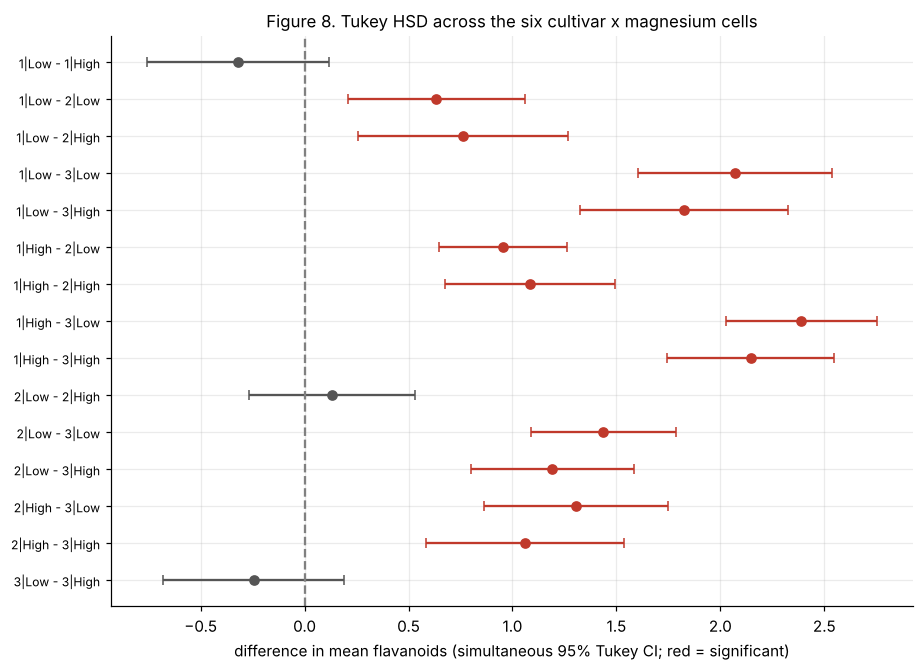

In [15]:
se_rows = []
for c in CULT:
    hi_ = df.loc[(df.cultivar == c) & (df.mg_level == "High Mg"), "flavanoids"].to_numpy(float); lo_ = df.loc[(df.cultivar == c) & (df.mg_level == "Low Mg"), "flavanoids"].to_numpy(float)
    d_, l_, u_, df_ = welch_ci(hi_, lo_); tt = stats.ttest_ind(hi_, lo_, equal_var=False)
    se_rows.append({"cultivar": c, "n_High": len(hi_), "n_Low": len(lo_), "High_minus_Low": d_, "CI95_low": l_, "CI95_high": u_, "t": tt.statistic, "df": df_, "p": tt.pvalue})
se = pd.DataFrame(se_rows); se["p_Bonferroni"] = np.minimum(1, se.p * 3); RESULTS["twoway"]["simple_effects"] = se.to_dict("records")
s_ = se.copy()
for col in ["High_minus_Low", "CI95_low", "CI95_high", "t", "df"]: s_[col] = s_[col].round(3)
for col in ["p", "p_Bonferroni"]: s_[col] = s_[col].map(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
display(Markdown("**Table 12. Simple effects: High-Mg minus Low-Mg flavanoids within each cultivar.**")); display(s_)

cell_names = [f"{c[-1]}|{m.split()[0]}" for c in CULT for m in MG]      # e.g. 1|Low
tk6 = tukey_table(cell_groups, cell_names); RESULTS["twoway"]["tukey_cells"] = tk6.to_dict("records")
t6 = tk6.copy()
for col in ["diff", "ci_low", "ci_high"]: t6[col] = t6[col].round(3)
t6["p_adj"] = t6["p_adj"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
display(Markdown("**Table 13. Tukey HSD on the 6 cells (labels = cultivar number | magnesium level; difference = first minus second).**")); display(t6)
n_sig = int(tk6.significant.sum())
within_c = [r.comparison for r in tk6.itertuples() if r.significant and r.comparison.split(" - ")[0][0] == r.comparison.split(" - ")[1][0]]
display(Markdown(f"**Tukey HSD:** {n_sig} of 15 cell pairs differ significantly; among the 3 pairs that differ *only* in magnesium level (same cultivar), "
                 f"{len(within_c)} are significant ({', '.join(within_c) if within_c else 'none'})."))

fig, ax = plt.subplots(figsize=(8.5, 6.2)); ypos = np.arange(len(tk6))[::-1]
colr = ["#c0392b" if s else "#555555" for s in tk6.significant]
for y_, (d_, l_, u_, c_) in zip(ypos, zip(tk6["diff"], tk6.ci_low, tk6.ci_high, colr)): ax.errorbar(d_, y_, xerr=[[d_ - l_], [u_ - d_]], fmt="o", color=c_, capsize=3)
ax.axvline(0, color="grey", ls="--"); ax.set_yticks(ypos); ax.set_yticklabels(tk6["comparison"], fontsize=8)
ax.set_xlabel("difference in mean flavanoids (simultaneous 95% Tukey CI; red = significant)"); ax.set_title("Figure 8. Tukey HSD across the six cultivar x magnesium cells")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig8_tukey_twoway_cells.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Summary of all hypothesis tests (computed from the results above)

In [16]:
rows = []
for v, r in RESULTS["two_sample"].items():
    for t in r["table"]:
        rows.append({"Section": "5", "Test": f"{t['Test']} ({v}, C1 vs C2)", "H0": "identical distributions" if "Mann" in t["Test"] else "equal means",
                     "Statistic": t["Statistic"], "p": t["p"], "Reject at 0.05": t["p"] < ALPHA})
o = RESULTS["oneway"]
rows += [{"Section": "6", "Test": f"One-way ANOVA F({o['dfb']}, {o['dfw']}) proline ~ cultivar", "H0": "3 equal means", "Statistic": o["F"], "p": o["p"], "Reject at 0.05": o["p"] < ALPHA},
         {"Section": "6", "Test": "Welch ANOVA (proline)", "H0": "3 equal means", "Statistic": o["welch_F"], "p": o["welch_p"], "Reject at 0.05": o["welch_p"] < ALPHA},
         {"Section": "6", "Test": "Kruskal-Wallis (proline)", "H0": "identical distributions", "Statistic": o["kruskal_H"], "p": o["kruskal_p"], "Reject at 0.05": o["kruskal_p"] < ALPHA}]
for r_ in RESULTS["twoway"]["type3"][:3]:
    rows.append({"Section": "7", "Test": f"Two-way ANOVA (Type III): {r_['Source']} (flavanoids)", "H0": "no effect", "Statistic": r_["F"], "p": r_["p"], "Reject at 0.05": r_["p"] < ALPHA})
summ = pd.DataFrame(rows); summ_out = summ.copy()
summ_out["Statistic"] = summ_out["Statistic"].round(3); summ_out["p"] = summ_out["p"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
display(Markdown("**Table 14. All omnibus and two-sample tests at alpha = 0.05.**")); display(summ_out)
summ.to_csv(RES_DIR / "all_tests_summary.csv", index=False)

def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if (isinstance(o, float) and math.isnan(o)) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
(RES_DIR / "results.json").write_text(json.dumps(_clean(RESULTS), indent=1))
print("Saved results/all_tests_summary.csv and results/results.json;", len(summ), "tests;", int(summ["Reject at 0.05"].sum()), "rejected at alpha = 0.05")

**Table 14. All omnibus and two-sample tests at alpha = 0.05.**

,Section,Test,H0,Statistic,p,Reject at 0.05
0,5,"Student t (equal var.) (alcohol, C1 vs C2)",equal means,16.479,<0.001,True
1,5,"Welch t (unequal var.) (alcohol, C1 vs C2)",equal means,16.711,<0.001,True
2,5,"Mann-Whitney U (alcohol, C1 vs C2)",identical distributions,4079.500,<0.001,True
3,5,"Student t (equal var.) (proline, C1 vs C2)",equal means,17.899,<0.001,True
4,5,"Welch t (unequal var.) (proline, C1 vs C2)",equal means,17.357,<0.001,True
5,5,"Mann-Whitney U (proline, C1 vs C2)",identical distributions,4133.000,<0.001,True
6,6,"One-way ANOVA F(2, 175) proline ~ cultivar",3 equal means,207.920,<0.001,True
7,6,Welch ANOVA (proline),3 equal means,153.841,<0.001,True
8,6,Kruskal-Wallis (proline),identical distributions,119.060,<0.001,True
9,7,Two-way ANOVA (Type III): cultivar (flavanoids),no effect,196.396,<0.001,True


Saved results/all_tests_summary.csv and results/results.json; 12 tests; 10 rejected at alpha = 0.05


## 9. Findings

In [17]:
two = RESULTS["two_sample"]; ow_ = RESULTS["oneway"]; tw = RESULTS["twoway"]
t3i = {r["Source"]: r for r in tw["type3"]}; rk3 = {r["Source"]: r for r in tw["rank_type3"]}
tkp = {r["comparison"]: r for r in ow_["tukey"]}; se_ = {r["cultivar"]: r for r in tw["simple_effects"]}
A, B_ = two["alcohol"], two["proline"]; SI = "cultivar x mg_level"
def verdict(p): return "significant" if p < ALPHA else "not significant"
def ci(r, i, f): return "[" + format(r["table"][i]["CI95_low"], f) + ", " + format(r["table"][i]["CI95_high"], f) + "]"
rej_samples = [r["variable"].replace("_", " ") + " / " + r["cultivar"][-1] for r in RESULTS["normality"] if not (r["SW_normal"] and r["KS_normal"])]
sig_simple = [c for c, r in se_.items() if r["p_Bonferroni"] < ALPHA]
sig_txt = ", ".join("Cultivar " + c[-1] for c in sig_simple) if sig_simple else "no cultivar"
within_pairs_sig = [r["comparison"] for r in tw["tukey_cells"] if r["significant"] and r["comparison"].split(" - ")[0][0] == r["comparison"].split(" - ")[1][0]]
methods_agree = (t3i[SI]["p"] < ALPHA) == (rk3[SI]["p"] < ALPHA)
simple_txt = "; ".join("Cultivar " + c[-1] + ": " + format(r["High_minus_Low"], "+.2f") + " (95% CI " + format(r["CI95_low"], ".2f") + " to " + format(r["CI95_high"], ".2f") + ", Bonferroni " + fmt_p(r["p_Bonferroni"]) + ")" for c, r in se_.items())
tk12, tk13, tk23 = tkp["Cultivar 1 - Cultivar 2"], tkp["Cultivar 1 - Cultivar 3"], tkp["Cultivar 2 - Cultivar 3"]
n_sw = sum(not r["SW_normal"] for r in RESULTS["normality"]); n_ks = sum(not r["KS_normal"] for r in RESULTS["normality"])
agree2 = all((r["table"][1]["p"] < ALPHA) == (r["table"][2]["p"] < ALPHA) for r in two.values())
bonf2 = all(min(r["table"][i]["p_Bonferroni"] for i in (1, 2)) < ALPHA for r in two.values())
n_tk_sig = sum(r["significant"] for r in tw["tukey_cells"])

text = f"""
### 9.1 Normality
* Shapiro-Wilk rejected normality in **{n_sw} of 12** samples and the Lilliefors-corrected Kolmogorov-Smirnov test in **{n_ks} of 12**. Samples where at least one test rejects (variable / cultivar number): {', '.join(rej_samples)}. Because some samples are non-normal, rank-based and robust checks accompany every parametric test (Figures 2 and 3).

### 9.2 Two-sample comparisons (Cultivar 1 vs Cultivar 2)
* **Alcohol:** mean {A['means'][0]:.2f} vs {A['means'][1]:.2f}; Welch t-test {verdict(A['table'][1]['p'])} ({fmt_p(A['table'][1]['p'])}), mean difference {A['table'][1]['Estimate']:.2f} with 95% CI {ci(A, 1, '.2f')}; Mann-Whitney U {verdict(A['table'][2]['p'])} ({fmt_p(A['table'][2]['p'])}). Hedges' g = {A['hedges_g'][0]:.2f} (a very large effect). Primary test by the pre-set rule: **{A['primary']}**.
* **Proline:** median {B_['medians'][0]:.0f} vs {B_['medians'][1]:.0f}; Welch t-test {verdict(B_['table'][1]['p'])} ({fmt_p(B_['table'][1]['p'])}), difference {B_['table'][1]['Estimate']:.0f} with 95% CI {ci(B_, 1, '.0f')}; Mann-Whitney U {verdict(B_['table'][2]['p'])} ({fmt_p(B_['table'][2]['p'])}), Hodges-Lehmann shift {B_['table'][2]['Estimate']:.0f} (95% CI {ci(B_, 2, '.0f')}). Hedges' g = {B_['hedges_g'][0]:.2f}. Primary test: **{B_['primary']}**.
* Parametric and non-parametric tests {'agree' if agree2 else 'disagree'} on significance for both comparisons, and both survive the Bonferroni correction for the two planned comparisons: **{bonf2}**.

### 9.3 One-way ANOVA and Tukey HSD (proline across cultivars)
* F({ow_['dfb']}, {ow_['dfw']}) = {ow_['F']:.1f}, {fmt_p(ow_['p'])}, eta-squared = {ow_['eta2']:.2f}: proline differs by cultivar. Residual normality (Shapiro-Wilk {fmt_p(ow_['shapiro_resid_p'])}) and equal variances (Levene {fmt_p(ow_['levene_p'])}) are both rejected, but Welch ANOVA ({fmt_p(ow_['welch_p'])}) and Kruskal-Wallis ({fmt_p(ow_['kruskal_p'])}) reach the same conclusion, so the result does not rest on those assumptions.
* Tukey HSD: Cultivar 1 vs 2 {verdict(tk12['p_adj'])} (diff {tk12['diff']:.0f}, 95% CI [{tk12['ci_low']:.0f}, {tk12['ci_high']:.0f}]); Cultivar 1 vs 3 {verdict(tk13['p_adj'])} (diff {tk13['diff']:.0f}, 95% CI [{tk13['ci_low']:.0f}, {tk13['ci_high']:.0f}]); Cultivar 2 vs 3 {verdict(tk23['p_adj'])} (diff {tk23['diff']:.0f}, 95% CI [{tk23['ci_low']:.0f}, {tk23['ci_high']:.0f}], {fmt_p(tk23['p_adj'])}). Games-Howell and Holm-adjusted Mann-Whitney give the same three decisions (Table 6), so the pairwise conclusions are also robust to unequal variances.

### 9.4 Two-way ANOVA (flavanoids ~ cultivar x magnesium level)
* **Cultivar main effect:** {verdict(t3i['cultivar']['p'])} (F = {t3i['cultivar']['F']:.1f}, {fmt_p(t3i['cultivar']['p'])}, partial eta-squared = {t3i['cultivar']['partial_eta2']:.2f}); the rank-based ANOVA agrees ({fmt_p(rk3['cultivar']['p'])}).
* **Magnesium main effect:** classical {verdict(t3i['mg_level']['p'])} (F = {t3i['mg_level']['F']:.2f}, {fmt_p(t3i['mg_level']['p'])}, partial eta-squared = {t3i['mg_level']['partial_eta2']:.3f}); rank-based {verdict(rk3['mg_level']['p'])} ({fmt_p(rk3['mg_level']['p'])}).
* **Interaction:** classical {verdict(t3i[SI]['p'])} (F = {t3i[SI]['F']:.2f}, {fmt_p(t3i[SI]['p'])}, partial eta-squared = {t3i[SI]['partial_eta2']:.3f}); rank-based {verdict(rk3[SI]['p'])} (F = {rk3[SI]['F']:.2f}, {fmt_p(rk3[SI]['p'])}). The two methods {'agree' if methods_agree else '**disagree**'}.
* **Assumptions:** the two-way residuals are not normal (Shapiro-Wilk {fmt_p(tw['shapiro_resid_p'])}) and cell variances are unequal (Levene {fmt_p(tw['levene_p'])}), so the classical interaction test, which sits right at the 0.05 boundary, should be read with caution. The evidence on the magnesium x cultivar interaction is therefore **borderline and method-dependent**, not settled.
* **Simple effects (High-Mg minus Low-Mg flavanoids):** {simple_txt}. After Bonferroni correction the magnesium difference is significant in: {sig_txt}.
* **Tukey HSD on the six cells:** {n_tk_sig} of 15 pairs differ significantly. **{len(within_pairs_sig)} of the 3** same-cultivar magnesium contrasts reach significance once the family-wise error over all 15 comparisons is controlled (Tukey is conservative and assumes equal variances, which is why it is less sensitive than the simple-effects tests above).

### 9.5 Overall interpretation and limits
* Cultivar is by far the dominant source of variation: proline and flavanoids differ enormously between cultivars (Hedges' g about 3 for the Cultivar 1 vs 2 contrasts; eta-squared about 0.70 for proline, partial eta-squared about 0.70 for flavanoids).
* Magnesium level has a much smaller association with flavanoids. It is {'significant' if t3i['mg_level']['p'] < ALPHA else 'not significant'} as a classical main effect, but the simple-effects analysis suggests a modest positive difference in {sig_txt}; this is reported as an exploratory pattern, not a firm conclusion.
* **Statistical vs practical significance:** the cultivar p-values are tiny because the effects are huge; effect sizes and CIs, not p-values alone, convey the size of the differences.
* **Limits:** the data are observational and come from one region and one era, so conclusions concern these wines, not wines in general. Magnesium was dichotomised at the median for the two-way design, which discards information and makes the design unbalanced (Type III results depend on effect coding). Each test was run at alpha = 0.05 with no overall correction across sections, except where a correction is stated (Tukey, Holm, Bonferroni). Wines are assumed to be independent observations.
"""
display(Markdown(text))


### 9.1 Normality
* Shapiro-Wilk rejected normality in **4 of 12** samples and the Lilliefors-corrected Kolmogorov-Smirnov test in **6 of 12**. Samples where at least one test rejects (variable / cultivar number): alcohol / 2, flavanoids / 2, flavanoids / 3, proline / 2, color intensity / 2, color intensity / 3. Because some samples are non-normal, rank-based and robust checks accompany every parametric test (Figures 2 and 3).

### 9.2 Two-sample comparisons (Cultivar 1 vs Cultivar 2)
* **Alcohol:** mean 13.74 vs 12.28; Welch t-test significant (p < 0.001), mean difference 1.47 with 95% CI [1.29, 1.64]; Mann-Whitney U significant (p < 0.001). Hedges' g = 2.89 (a very large effect). Primary test by the pre-set rule: **Welch t-test**.
* **Proline:** median 1095 vs 495; Welch t-test significant (p < 0.001), difference 596 with 95% CI [528, 664]; Mann-Whitney U significant (p < 0.001), Hodges-Lehmann shift 601 (95% CI [533, 665]). Hedges' g = 3.13. Primary test: **Mann-Whitney U**.
* Parametric and non-parametric tests agree on significance for both comparisons, and both survive the Bonferroni correction for the two planned comparisons: **True**.

### 9.3 One-way ANOVA and Tukey HSD (proline across cultivars)
* F(2, 175) = 207.9, p < 0.001, eta-squared = 0.70: proline differs by cultivar. Residual normality (Shapiro-Wilk p = 0.021) and equal variances (Levene p < 0.001) are both rejected, but Welch ANOVA (p < 0.001) and Kruskal-Wallis (p < 0.001) reach the same conclusion, so the result does not rest on those assumptions.
* Tukey HSD: Cultivar 1 vs 2 significant (diff 596, 95% CI [524, 668]); Cultivar 1 vs 3 significant (diff 486, 95% CI [407, 565]); Cultivar 2 vs 3 significant (diff -110, 95% CI [-187, -34], p = 0.002). Games-Howell and Holm-adjusted Mann-Whitney give the same three decisions (Table 6), so the pairwise conclusions are also robust to unequal variances.

### 9.4 Two-way ANOVA (flavanoids ~ cultivar x magnesium level)
* **Cultivar main effect:** significant (F = 196.4, p < 0.001, partial eta-squared = 0.70); the rank-based ANOVA agrees (p < 0.001).
* **Magnesium main effect:** classical not significant (F = 2.89, p = 0.091, partial eta-squared = 0.017); rank-based not significant (p = 0.073).
* **Interaction:** classical not significant (F = 2.86, p = 0.060, partial eta-squared = 0.032); rank-based significant (F = 4.84, p = 0.009). The two methods **disagree**.
* **Assumptions:** the two-way residuals are not normal (Shapiro-Wilk p < 0.001) and cell variances are unequal (Levene p < 0.001), so the classical interaction test, which sits right at the 0.05 boundary, should be read with caution. The evidence on the magnesium x cultivar interaction is therefore **borderline and method-dependent**, not settled.
* **Simple effects (High-Mg minus Low-Mg flavanoids):** Cultivar 1: +0.32 (95% CI 0.09 to 0.56, Bonferroni p = 0.029); Cultivar 2: -0.13 (95% CI -0.61 to 0.34, Bonferroni p = 1.000); Cultivar 3: +0.24 (95% CI 0.07 to 0.42, Bonferroni p = 0.021). After Bonferroni correction the magnesium difference is significant in: Cultivar 1, Cultivar 3.
* **Tukey HSD on the six cells:** 12 of 15 pairs differ significantly. **0 of the 3** same-cultivar magnesium contrasts reach significance once the family-wise error over all 15 comparisons is controlled (Tukey is conservative and assumes equal variances, which is why it is less sensitive than the simple-effects tests above).

### 9.5 Overall interpretation and limits
* Cultivar is by far the dominant source of variation: proline and flavanoids differ enormously between cultivars (Hedges' g about 3 for the Cultivar 1 vs 2 contrasts; eta-squared about 0.70 for proline, partial eta-squared about 0.70 for flavanoids).
* Magnesium level has a much smaller association with flavanoids. It is not significant as a classical main effect, but the simple-effects analysis suggests a modest positive difference in Cultivar 1, Cultivar 3; this is reported as an exploratory pattern, not a firm conclusion.
* **Statistical vs practical significance:** the cultivar p-values are tiny because the effects are huge; effect sizes and CIs, not p-values alone, convey the size of the differences.
* **Limits:** the data are observational and come from one region and one era, so conclusions concern these wines, not wines in general. Magnesium was dichotomised at the median for the two-way design, which discards information and makes the design unbalanced (Type III results depend on effect coding). Each test was run at alpha = 0.05 with no overall correction across sections, except where a correction is stated (Tukey, Holm, Bonferroni). Wines are assumed to be independent observations.


In [18]:
# Consistency guard: the written findings above are generated from the results; these assertions fail loudly
# if a re-run on different data would make the narrative claims untrue.
assert all(r["primary_p"] < ALPHA for r in RESULTS["two_sample"].values()), "two-sample claim"
assert RESULTS["oneway"]["p"] < ALPHA and RESULTS["oneway"]["welch_p"] < ALPHA and RESULTS["oneway"]["kruskal_p"] < ALPHA, "one-way claim"
assert t3i["cultivar"]["p"] < ALPHA and rk3["cultivar"]["p"] < ALPHA, "two-way cultivar claim"
print("Consistency guard passed.")

Consistency guard passed.
